# Interpretabilidad de los modelos y comportamiento de compra

### Predicción de intención de compra en tiendas online

**Objetivo:** comprender qué características influyen en las predicciones de los modelos y analizar su relación con el comportamiento de compra observado.

En este notebook estudiaremos la interpretabilidad de dos modelos mediante SHAP:

- **CatBoost (Gradient Boosting):** uno de los modelos con mejores resultados durante la experimentación, que utiliza las 17 características originales y cinco variables derivadas.
- **Random Forest:** modelo seleccionado finalmente en el notebook 05, que utiliza las 17 características originales.

Inicialmente, el análisis de interpretabilidad se centró en CatBoost. Tras la evaluación final y la selección de Random Forest, se amplió el estudio para incluir también el modelo definitivo utilizado en la aplicación NEXUS.

Analizaremos ambos modelos por separado, estudiando la importancia global de sus características, la dirección de sus contribuciones y las explicaciones de sesiones individuales. Posteriormente, contrastaremos algunos patrones con las tasas reales de conversión y compararemos los principales hallazgos.

El objetivo no es únicamente comprender cómo predicen los modelos, sino identificar patrones de navegación que puedan resultar útiles desde una perspectiva empresarial, sin confundir las asociaciones predictivas con relaciones causales.

## 1. Preparación de los datos y fundamentos

Comenzamos reproduciendo la limpieza y la partición estratificada utilizadas en los notebooks anteriores, manteniendo la semilla 42.

Trabajaremos con el conjunto de entrenamiento para realizar los análisis de interpretabilidad, sin utilizar el conjunto de prueba reservado para la evaluación final.

A partir de estos datos prepararemos las entradas correspondientes a cada modelo: CatBoost con 22 características y Random Forest con las 17 originales.

Antes de analizar sus predicciones, introduciremos brevemente el funcionamiento de SHAP y las diferencias necesarias para interpretar correctamente sus contribuciones.

In [28]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.special import expit
from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier, Pool

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold"
})

# Carga y división del dataset

RAIZ = Path.cwd().resolve()

if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

datos = pd.read_csv(
    RAIZ / "data" / "raw" / "online_shoppers_intention.csv"
)

datos = datos.drop_duplicates().reset_index(drop=True)

X = datos.drop(columns="Revenue")
y = datos["Revenue"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

variables_categoricas = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

print(f"Entrenamiento: {len(X_train):,} sesiones")
print(f"Prueba reservada: {len(X_test):,} sesiones")

Entrenamiento: 9,764 sesiones
Prueba reservada: 2,441 sesiones


### 1.1. Fundamentos de SHAP

Para interpretar las predicciones utilizaremos **SHAP (SHapley Additive exPlanations)**, un método que permite descomponer la salida de un modelo en las contribuciones de sus características.

Para una sesión concreta, esta descomposición se expresa como:

$$
f(x) = \phi_0 + \sum_{j=1}^{p}\phi_j(x)
$$

Donde:

- $\phi_0$ es el valor base o de referencia de la salida del modelo.
- $\phi_j(x)$ representa la contribución de cada característica.
- Una contribución positiva aumenta la salida respecto al valor base, mientras que una negativa la reduce.

Esta descomposición permite realizar dos tipos de análisis:

- **Interpretabilidad global:** identificar las características más influyentes mediante la media del valor absoluto de sus contribuciones SHAP.
- **Interpretabilidad local:** explicar cómo intervienen las distintas características en la predicción de una sesión concreta.

Aunque utilizaremos SHAP en ambos modelos, existe una diferencia importante en la escala de las contribuciones:

- **CatBoost:** analizaremos las contribuciones en *log-odds*. Para obtener la probabilidad de compra, debemos aplicar la función logística a la suma del valor base y las contribuciones.
- **Random Forest:** explicaremos directamente la probabilidad estimada de compra. Las contribuciones podrán interpretarse como variaciones de dicha probabilidad respecto a su valor de referencia.

Por tanto, las magnitudes SHAP de ambos modelos no serán directamente comparables. En la comparación final nos centraremos en las características que destacan, sus patrones de contribución y las diferencias entre los modelos.

Finalmente, debemos recordar que **SHAP explica las predicciones del modelo, no relaciones de causa y efecto**. Una característica puede tener una contribución elevada sin que modificarla provoque necesariamente un cambio en el comportamiento de compra.

## 2. Interpretabilidad de CatBoost (Gradient Boosting)

Comenzamos con CatBoost, uno de los modelos que mejores resultados obtuvo durante la comparación y optimización realizadas en los notebooks anteriores.

Este modelo incorpora cinco características derivadas de las variables originales, por lo que trabaja con un total de 22 características.

Analizaremos primero su importancia global y las contribuciones SHAP de las diferentes variables. Después estudiaremos algunas relaciones concretas, una versión alternativa sin `PageValues` y las explicaciones de sesiones individuales.

Aunque finalmente seleccionamos Random Forest como modelo definitivo, conservamos este análisis porque permite comprender el comportamiento de otro de los modelos más competitivos del proyecto.

### 2.1. Ingeniería de características

Recuperamos las cinco variables derivadas utilizadas durante los experimentos de CatBoost para reproducir exactamente su configuración de entrada.

In [29]:
# Ingeniería de características

def crear_caracteristicas(X):
    X = X.copy()

    X["Has_PageValue"] = (X["PageValues"] > 0).astype(int)

    X["Total_Pages"] = (
        X["Administrative"]
        + X["Informational"]
        + X["ProductRelated"]
    )

    X["Total_Duration"] = (
        X["Administrative_Duration"]
        + X["Informational_Duration"]
        + X["ProductRelated_Duration"]
    )

    X["Avg_Product_Time"] = (
        X["ProductRelated_Duration"]
        / X["ProductRelated"].clip(lower=1)
    )

    X["Product_Page_Share"] = (
        X["ProductRelated"]
        / X["Total_Pages"].clip(lower=1)
    )

    return X


X_train_cb = crear_caracteristicas(X_train)

for columna in variables_categoricas:
    X_train_cb[columna] = X_train_cb[columna].astype(str)

print(f"Características utilizadas: {X_train_cb.shape[1]}")

Características utilizadas: 22


### 2.2. Entrenamiento de CatBoost

Reconstruimos el modelo con los hiperparámetros seleccionados
tras la búsqueda aleatoria y su refinamiento:

- iterations = 300
- depth = 8
- learning_rate = 0.02
- l2_leaf_reg = 1

No aplicamos ponderación de clases ni sobremuestreo, dado que
los experimentos anteriores no mostraron mejoras relevantes.

In [30]:
# CatBoost seleccionado

modelo_cb = CatBoostClassifier(
    iterations=300,
    depth=8,
    learning_rate=0.02,
    l2_leaf_reg=1,
    loss_function="Logloss",
    random_seed=RANDOM_STATE,
    thread_count=4,
    verbose=False,
    allow_writing_files=False
)

modelo_cb.fit(
    X_train_cb,
    y_train,
    cat_features=variables_categoricas
)

print("CatBoost entrenado correctamente.")
print(f"Características: {len(modelo_cb.feature_names_)}")

CatBoost entrenado correctamente.
Características: 22


### 2.3. Cálculo de las contribuciones SHAP

Calculamos las contribuciones SHAP de CatBoost utilizando una muestra reproducible de 1.000 sesiones del conjunto de entrenamiento. Esto nos permite estudiar el comportamiento del modelo sin necesidad de procesar todas las sesiones.

Para cada sesión obtenemos las contribuciones de sus 22 características y un valor base. En este modelo, las contribuciones están expresadas en **log-odds**, por lo que su suma reconstruye la salida del modelo antes de convertirla en una probabilidad.

También comprobaremos que dicha reconstrucción coincide con la predicción original de CatBoost. Una vez calculados estos valores, podremos estudiar qué características tienen mayor influencia y cómo afectan a las predicciones.

In [31]:
# Muestra reproducible de sesiones de entrenamiento
muestra_shap = X_train_cb.sample(
    n=1000,
    random_state=RANDOM_STATE
)

pool_shap = Pool(
    muestra_shap,
    cat_features=variables_categoricas
)

# Contribuciones SHAP y valor base
valores_shap = modelo_cb.get_feature_importance(
    data=pool_shap,
    type="ShapValues"
)

contribuciones = pd.DataFrame(
    valores_shap[:, :-1],
    index=muestra_shap.index,
    columns=muestra_shap.columns
)

valores_base = valores_shap[:, -1]

# Importancia global: media de las contribuciones absolutas
importancia_shap = (
    contribuciones.abs()
    .mean()
    .sort_values(ascending=False)
)

print(f"Sesiones analizadas: {len(muestra_shap):,}")
print(f"Características explicadas: {contribuciones.shape[1]}")
print(f"Dimensiones SHAP: {valores_shap.shape}")

# Comprobar que SHAP reconstruye las predicciones
predicciones_raw = modelo_cb.predict(
    pool_shap,
    prediction_type="RawFormulaVal"
).ravel()

reconstruccion = (
    valores_base + contribuciones.sum(axis=1).to_numpy()
)

error_maximo = np.max(
    np.abs(predicciones_raw - reconstruccion)
)

print(f"Error máximo de reconstrucción: {error_maximo:.2e}")

assert np.allclose(
    predicciones_raw,
    reconstruccion,
    atol=1e-5
), "Las contribuciones SHAP no reconstruyen las predicciones."

Sesiones analizadas: 1,000
Características explicadas: 22
Dimensiones SHAP: (1000, 23)
Error máximo de reconstrucción: 1.07e-14


### 2.4. Importancia global de las características

Calculamos la importancia global de cada característica mediante la media del valor absoluto de sus contribuciones SHAP sobre las 1.000 sesiones seleccionadas.

Esta medida permite identificar qué variables tienen mayor influencia en las predicciones de CatBoost, independientemente de si sus contribuciones son positivas o negativas.

Representamos las 15 características más importantes, ordenadas según su contribución media absoluta. Los valores están expresados en **log-odds**, por lo que no representan cambios directos en puntos porcentuales de probabilidad.

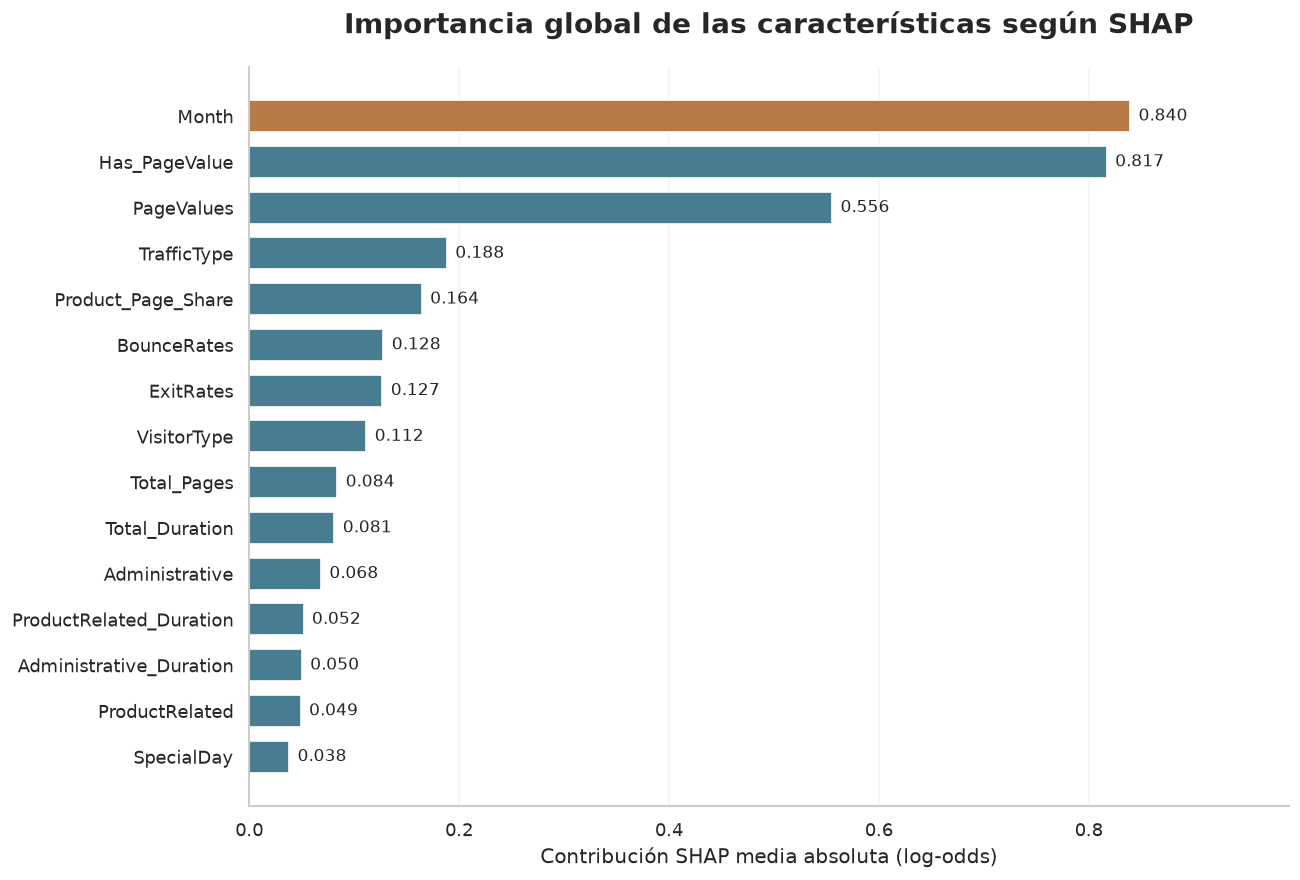

In [32]:
top_importancia = importancia_shap.head(15).sort_values()

fig, ax = plt.subplots(figsize=(11, 7.5))

colores = [
    "#B77946" if variable == importancia_shap.index[0]
    else "#487D91"
    for variable in top_importancia.index
]

barras = ax.barh(
    top_importancia.index,
    top_importancia.values,
    color=colores,
    height=0.7
)

ax.bar_label(
    barras,
    fmt="%.3f",
    padding=5,
    fontsize=10
)

ax.set_xlim(0, top_importancia.max() * 1.18)

ax.set_title(
    "Importancia global de las características según SHAP",
    fontsize=17,
    pad=20
)

ax.set_xlabel(
    "Contribución SHAP media absoluta (log-odds)"
)
ax.set_ylabel("")

ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Interpretación**

- **Month (0,840)** es la característica más influyente, lo
  que sugiere que la estacionalidad desempeña un papel
  importante en las predicciones del modelo.


- **Has_PageValue (0,817) y PageValues (0,556)** destacan
  conjuntamente, en consonancia con la fuerte dependencia
  de esta información observada en el notebook 03.


- **TrafficType (0,188)** y variables de navegación como
  Product_Page_Share, BounceRates y ExitRates también
  contribuyen a las predicciones, aunque en menor medida.

- **Product_Page_Share (0,164)** es una de las características
derivadas más importantes, lo que sugiere que la proporción de 
páginas de productos visitadas aporta información útil al modelo.

Vemos que CatBoost combina información temporal, indicadores del valor de las páginas y características de navegación para realizar sus predicciones.

No obstante, este gráfico únicamente muestra la **magnitud media de las contribuciones**. Para comprender qué valores aumentan o reducen las predicciones, analizaremos su dirección en el siguiente apartado.

### 2.5. Dirección de las contribuciones SHAP

La importancia global nos indica qué características tienen mayor influencia, pero no si aumentan o reducen las predicciones de compra.

Para estudiar esta cuestión, representamos la distribución de las contribuciones SHAP de las 13 características más importantes en las 1.000 sesiones analizadas.

Cada punto representa una sesión:

- **Posición horizontal:** contribución SHAP. Los valores positivos aumentan la predicción respecto al valor base y los negativos la reducen.
- **Color:** para las características numéricas, azul indica valores bajos y rojo valores altos, normalizados por separado para cada característica.
- **Gris:** características categóricas, cuyos valores no tienen necesariamente un orden cuantitativo.

Las contribuciones siguen expresadas en *log-odds*. El gráfico permite identificar patrones generales, aunque la contribución de una característica puede variar entre sesiones debido a las interacciones aprendidas por el modelo.

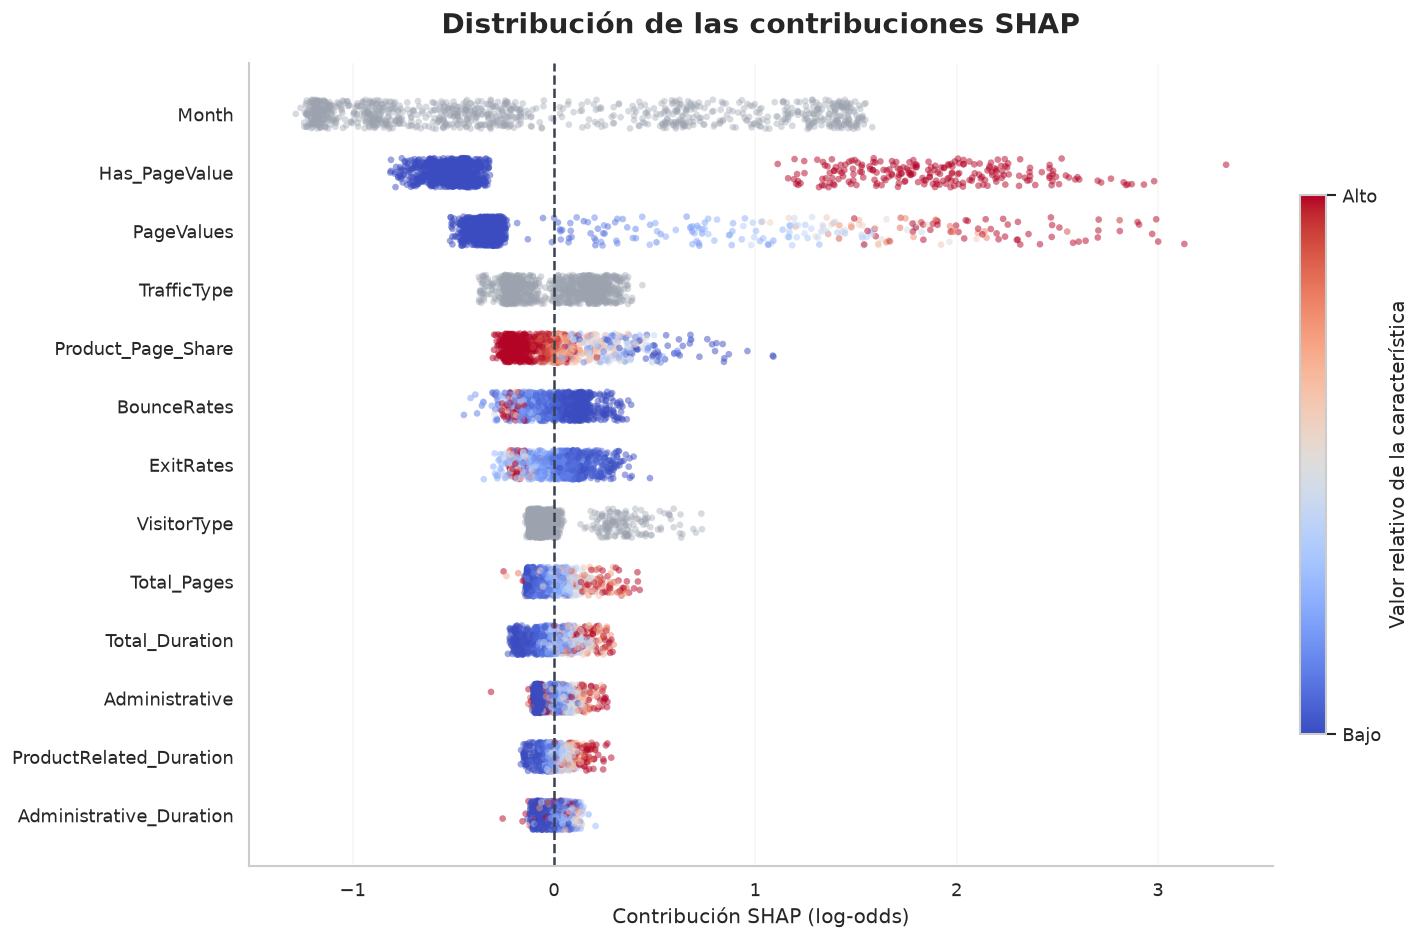

In [33]:
top_variables = importancia_shap.head(13).index[::-1]
rng = np.random.default_rng(RANDOM_STATE)

fig, ax = plt.subplots(figsize=(12, 8))

for i, variable in enumerate(top_variables):

    shap_vals = contribuciones[variable].to_numpy()
    posiciones = i + rng.uniform(-0.25, 0.25, len(shap_vals))

    if variable in variables_categoricas:
        ax.scatter(
            shap_vals, posiciones,
            color="#9CA3AF",
            s=16, alpha=0.4,
            edgecolors="none",
            rasterized=True
        )
    else:
        valores = muestra_shap[variable].astype(float).to_numpy()
        p5, p95 = np.percentile(valores, [5, 95])

        if p95 > p5:
            colores = np.clip(
                (valores - p5) / (p95 - p5), 0, 1
            )
        else:
            colores = np.full(len(valores), 0.5)

        ax.scatter(
            shap_vals, posiciones,
            c=colores,
            cmap="coolwarm",
            vmin=0, vmax=1,
            s=16, alpha=0.5,
            edgecolors="none",
            rasterized=True
        )

ax.axvline(
    0, color="#374151",
    linestyle="--", linewidth=1.5
)

ax.set_yticks(range(len(top_variables)))
ax.set_yticklabels(top_variables)

ax.set_title(
    "Distribución de las contribuciones SHAP",
    fontsize=17, pad=18
)

ax.set_xlabel("Contribución SHAP (log-odds)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.15)
ax.grid(axis="y", visible=False)

escala = plt.cm.ScalarMappable(
    norm=plt.Normalize(0, 1),
    cmap="coolwarm"
)

barra = fig.colorbar(
    escala, ax=ax,
    fraction=0.025, pad=0.025
)

barra.set_ticks([0, 1])
barra.set_ticklabels(["Bajo", "Alto"])
barra.set_label("Valor relativo de la característica")

plt.tight_layout()
plt.show()

**Interpretación**

- **PageValues y Has_PageValue:** los valores positivos elevan
  claramente la predicción de compra, mientras que los valores
  nulos presentan contribuciones negativas.


- **Month:** muestra contribuciones positivas y negativas muy
  diferenciadas. Analizaremos qué meses explican este patrón.


- **BounceRates y ExitRates:** los valores elevados
  reducen la predicción de compra, mientras que los bajos
  presentan contribuciones más favorables.


- **Intensidad de navegación:** mayores valores de Total_Pages
  y Total_Duration suelen contribuir positivamente.

  
- **Product_Page_Share:** los valores altos muestran una
  contribución predominantemente negativa, un resultado que
  requiere cautela por su relación con otras variables.

Vemos que CatBoost combina información sobre el valor de las páginas, la estacionalidad y el comportamiento de navegación. La dirección de las contribuciones no es siempre uniforme, puesto que depende de cómo el modelo utiliza cada característica junto con las demás.

Estas relaciones describen **el comportamiento predictivo de CatBoost**, 
pero no demuestran que modificar dichas características provoque un cambio
 en la probabilidad real de compra.

### 2.6. Influencia del mes de visita

`Month` es la característica con mayor importancia global según SHAP en CatBoost. Por ello, analizamos con más detalle cómo contribuyen los distintos meses a las predicciones de compra.

Al tratarse de una variable categórica, calculamos la **contribución SHAP media de cada mes** sobre las 1.000 sesiones seleccionadas.

- Una contribución media positiva indica que ese mes tiende a aumentar la predicción respecto al valor base del modelo.
- Una contribución media negativa indica que tiende a reducirla.
- El número de sesiones de cada mes permite valorar la representatividad de los resultados.

Las contribuciones están expresadas en *log-odds* y no equivalen directamente a probabilidades ni a tasas de conversión observadas.

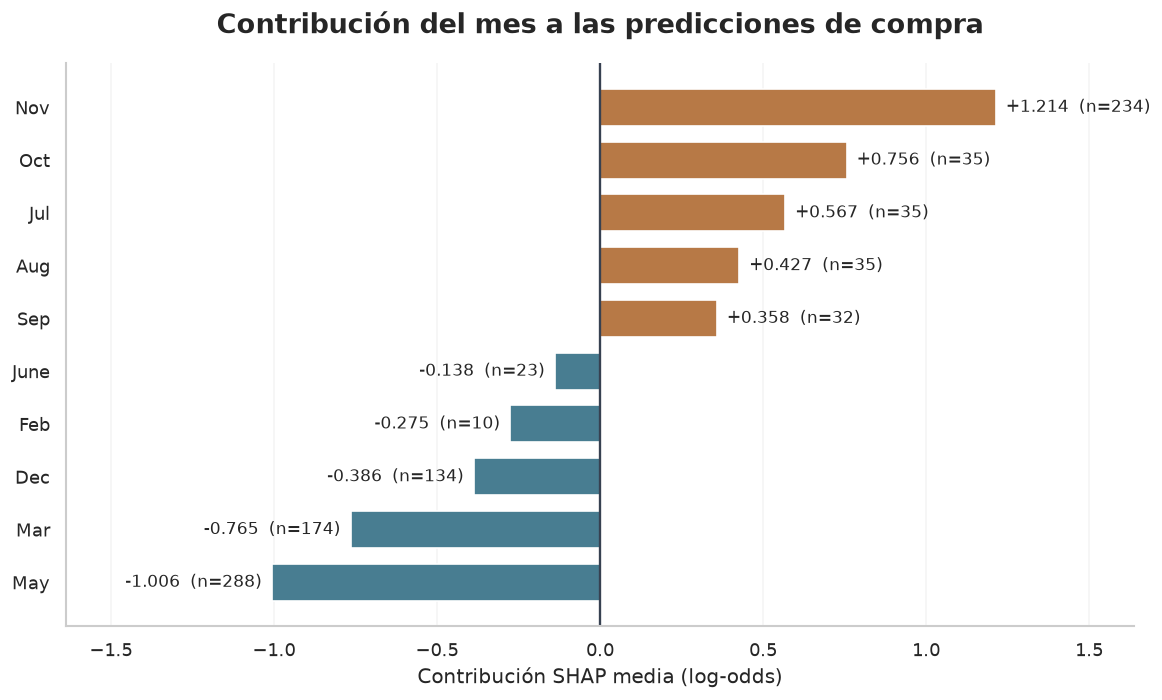

In [34]:
tabla_meses = pd.DataFrame({
    "Mes": muestra_shap["Month"],
    "SHAP": contribuciones["Month"]
})

resumen_meses = (
    tabla_meses
    .groupby("Mes")["SHAP"]
    .agg(["mean", "size"])
    .rename(columns={
        "mean": "SHAP medio",
        "size": "Sesiones"
    })
    .sort_values("SHAP medio")
)

colores = [
    "#B77946" if valor > 0 else "#487D91"
    for valor in resumen_meses["SHAP medio"]
]

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    resumen_meses.index,
    resumen_meses["SHAP medio"],
    color=colores,
    height=0.7
)

ax.axvline(
    0,
    color="#374151",
    linewidth=1.4
)

limite = resumen_meses["SHAP medio"].abs().max() * 1.35
ax.set_xlim(-limite, limite)

for barra, valor, n in zip(
    barras,
    resumen_meses["SHAP medio"],
    resumen_meses["Sesiones"]
):
    ax.annotate(
        f"{valor:+.3f}  (n={n})",
        (valor, barra.get_y() + barra.get_height() / 2),
        xytext=(6 if valor >= 0 else -6, 0),
        textcoords="offset points",
        va="center",
        ha="left" if valor >= 0 else "right",
        fontsize=10
    )

ax.set_title(
    "Contribución del mes a las predicciones de compra",
    fontsize=16,
    pad=18
)

ax.set_xlabel("Contribución SHAP media (log-odds)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

**Interpretación**

- **Noviembre (+1,214)** presenta la mayor contribución positiva, seguido de octubre (+0,756). Esto coincide con las mayores tasas de conversión observadas en el EDA.


- **Mayo (−1,006)** y marzo (−0,765) presentan las contribuciones más negativas, asociándose con predicciones de compra inferiores.


- **Diciembre (−0,386)** también tiene una contribución negativa, a pesar de su proximidad a noviembre.


- Los resultados de meses poco representados, como febrero (10 sesiones en la muestra), tendriamos que interpretarlos con cautela.

**Conclusión:** CatBoost utiliza de forma importante la estacionalidad para diferenciar sesiones. No obstante, estas contribuciones describen patrones aprendidos del dataset, no efectos causales del mes sobre la compra.

### 2.7. Relación entre los valores de las características y sus contribuciones

Analizamos cómo varían las contribuciones SHAP de `PageValues`, `ExitRates` y `Product_Page_Share` según sus valores.

Esto permite identificar patrones que no se observan en la importancia global. Para visualizar mejor `PageValues`, utilizamos `log(1 + PageValues)` en el eje horizontal, manteniendo las contribuciones SHAP en *log-odds*.

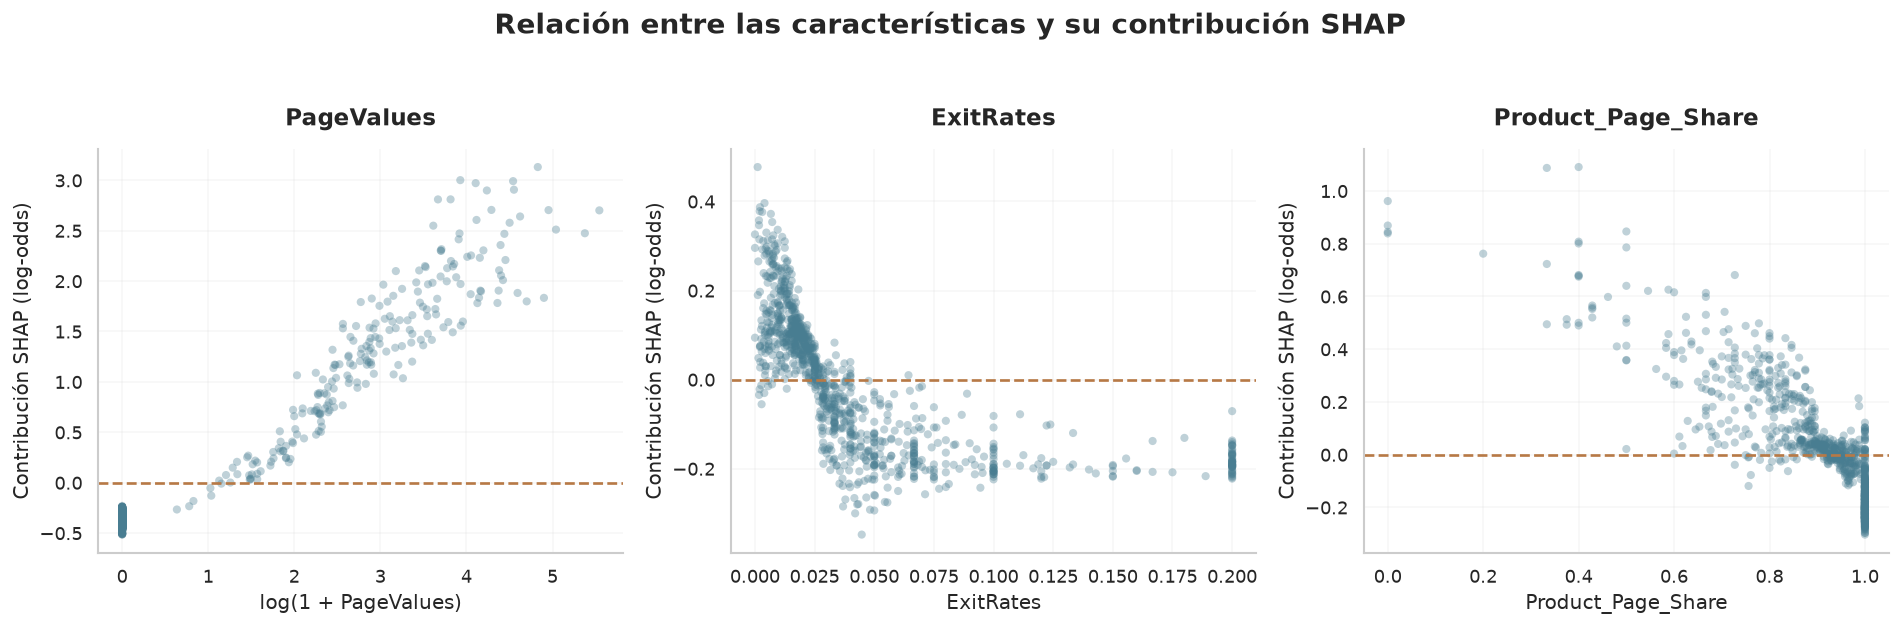

In [35]:
variables_dependencia = [
    "PageValues",
    "ExitRates",
    "Product_Page_Share"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, variable in zip(axes, variables_dependencia):

    valores = muestra_shap[variable].astype(float)
    shap_vals = contribuciones[variable]

    if variable == "PageValues":
        x = np.log1p(valores)
        etiqueta_x = "log(1 + PageValues)"
    else:
        x = valores
        etiqueta_x = variable

    ax.scatter(
        x,
        shap_vals,
        color="#487D91",
        s=24,
        alpha=0.35,
        edgecolors="none",
        rasterized=True
    )

    ax.axhline(
        0,
        color="#B77946",
        linestyle="--",
        linewidth=1.6
    )

    ax.set_title(variable, fontsize=14, pad=14)
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel("Contribución SHAP (log-odds)")
    ax.grid(alpha=0.15)

fig.suptitle(
    "Relación entre las características y su contribución SHAP",
    fontsize=17,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

**Interpretación**

- **PageValues:** presenta una relación positiva muy clara. Los valores nulos reducen la puntuación de compra, mientras que las contribuciones aumentan progresivamente con su magnitud.


- **ExitRates:** las tasas bajas contribuyen positivamente, mientras que a partir de aproximadamente 0,03 predominan las contribuciones negativas. Es una señal relevante para investigar el abandono.


- **Product_Page_Share:** las proporciones intermedias muestran contribuciones frecuentemente positivas, mientras que los valores cercanos a 1 tienden a ser neutros o negativos.

**Hallazgo relevante:** una navegación concentrada exclusivamente en páginas de productos no implica necesariamente mayor intención de compra. Esto podría reflejar diferencias en los patrones de navegación, aunque no permite identificar por sí solo una causa de abandono.

### 2.8. Interpretabilidad sin PageValues

Los experimentos anteriores demostraron una fuerte dependencia de `PageValues`: al eliminarla, el Average Precision de CatBoost disminuyó de aproximadamente 0,757 a 0,387.

Para investigar las restantes señales de navegación, analizaremos un segundo CatBoost entrenado sin `PageValues` ni `Has_PageValue`.

Utilizaremos las 20 características restantes y la configuración seleccionada para este escenario en el notebook 03.

#### 2.8.1. Importancia global sin PageValues

In [36]:
X_train_sin_page = X_train_cb.drop(
    columns=["PageValues", "Has_PageValue"]
).copy()

modelo_cb_sin_page = CatBoostClassifier(
    iterations=300,
    depth=8,
    learning_rate=0.03,
    l2_leaf_reg=3,
    loss_function="Logloss",
    random_seed=RANDOM_STATE,
    thread_count=4,
    verbose=False,
    allow_writing_files=False
)

modelo_cb_sin_page.fit(
    X_train_sin_page,
    y_train,
    cat_features=variables_categoricas
)

# Mismas 1.000 sesiones utilizadas en el análisis anterior
muestra_sin_page = muestra_shap.drop(
    columns=["PageValues", "Has_PageValue"]
)

pool_sin_page = Pool(
    muestra_sin_page,
    cat_features=variables_categoricas
)

valores_shap_sin_page = modelo_cb_sin_page.get_feature_importance(
    data=pool_sin_page,
    type="ShapValues"
)

contribuciones_sin_page = pd.DataFrame(
    valores_shap_sin_page[:, :-1],
    index=muestra_sin_page.index,
    columns=muestra_sin_page.columns
)

importancia_sin_page = (
    contribuciones_sin_page.abs()
    .mean()
    .sort_values(ascending=False)
)

print("Modelo alternativo entrenado correctamente.")
print(f"Características: {len(modelo_cb_sin_page.feature_names_)}")

display(
    importancia_sin_page.head(10)
    .to_frame("SHAP medio absoluto")
    .style.format("{:.4f}")
)

Modelo alternativo entrenado correctamente.
Características: 20


,SHAP medio absoluto
Month,0.3750
ExitRates,0.3720
ProductRelated_Duration,0.2218
TrafficType,0.1981
Avg_Product_Time,0.1712
Product_Page_Share,0.1556
BounceRates,0.1517
Total_Duration,0.1473
VisitorType,0.1198
Administrative,0.1110


**Interpretación**

- **Month (0,3750) y ExitRates (0,3720)** son las características más influyentes del modelo sin PageValues.


- **ProductRelated_Duration (0,2218)** y **TrafficType (0,1981)** también destacan, lo que señala la relevancia de la navegación por productos y del origen del tráfico.


- Entre las variables derivadas aparecen **Avg_Product_Time (0,1712)** y **Product_Page_Share (0,1556)**, relacionadas con la intensidad y distribución de la navegación.


- **BounceRates (0,1517)** refuerza el interés por analizar los patrones de abandono.

**Siguiente paso:** estudiaremos la dirección de estas contribuciones para identificar comportamientos asociados con predicciones de compra más bajas.

#### 2.8.2. Dirección de las contribuciones sin PageValues

Representamos las contribuciones SHAP de las 12 características más importantes del modelo alternativo.

Cada punto corresponde a una sesión. Su posición horizontal indica si la característica aumenta o reduce la puntuación de compra, mientras que el color representa el valor relativo de las variables numéricas.

Este análisis permitirá identificar patrones de navegación relevantes para investigar posibles barreras de conversión, sin confundir las contribuciones predictivas con efectos causales.

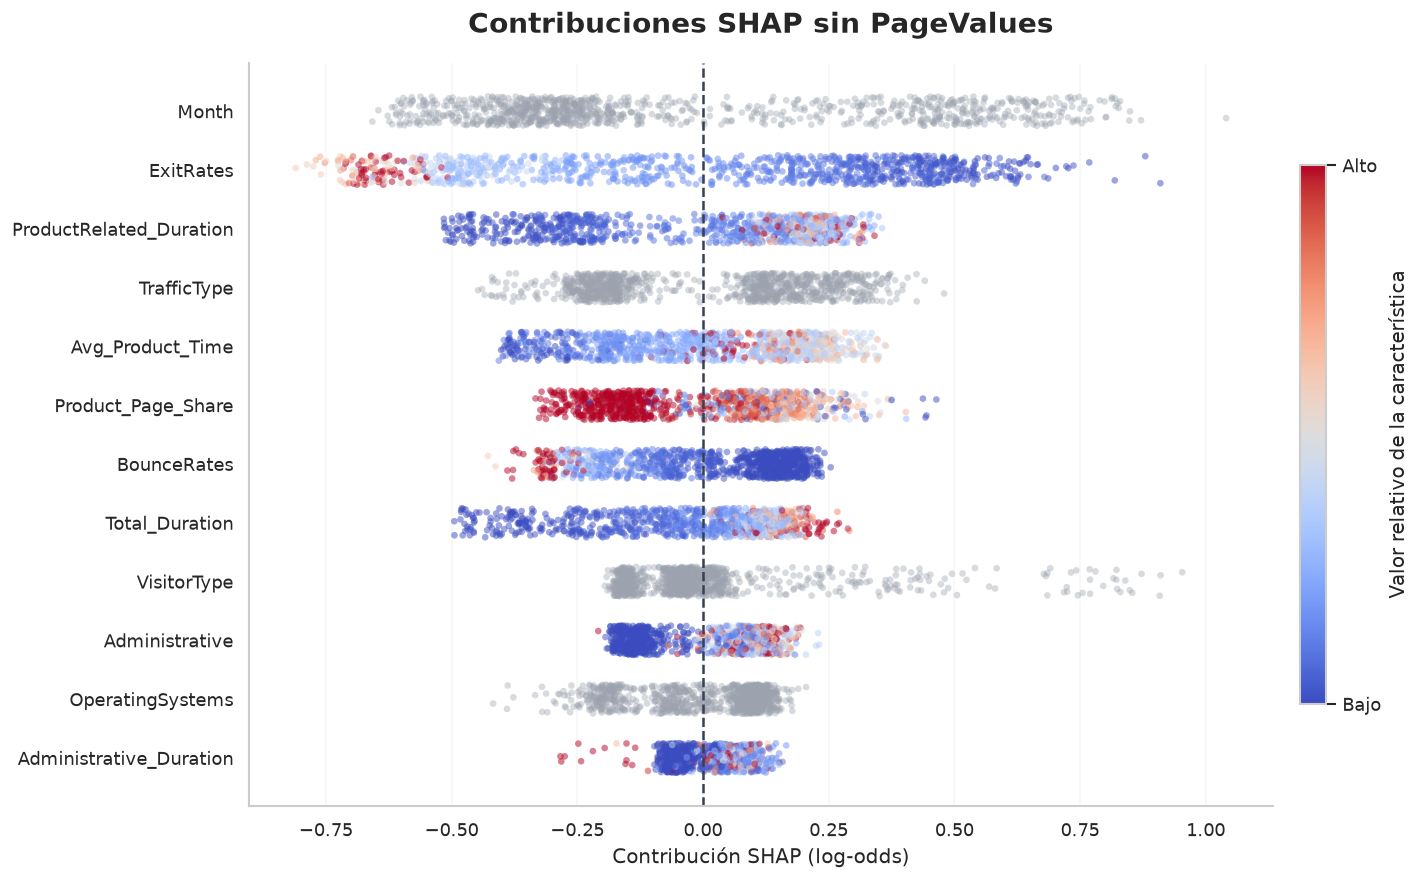

In [37]:
top_variables_sp = importancia_sin_page.head(12).index[::-1]
rng = np.random.default_rng(RANDOM_STATE)

fig, ax = plt.subplots(figsize=(12, 7.5))

for i, variable in enumerate(top_variables_sp):

    shap_vals = contribuciones_sin_page[variable].to_numpy()
    posiciones = i + rng.uniform(-0.25, 0.25, len(shap_vals))

    if variable in variables_categoricas:
        ax.scatter(
            shap_vals, posiciones,
            color="#9CA3AF",
            s=16, alpha=0.4,
            edgecolors="none",
            rasterized=True
        )
    else:
        valores = muestra_sin_page[variable].astype(float).to_numpy()
        p5, p95 = np.percentile(valores, [5, 95])

        if p95 > p5:
            colores = np.clip(
                (valores - p5) / (p95 - p5), 0, 1
            )
        else:
            colores = np.full(len(valores), 0.5)

        ax.scatter(
            shap_vals, posiciones,
            c=colores,
            cmap="coolwarm",
            vmin=0, vmax=1,
            s=16, alpha=0.5,
            edgecolors="none",
            rasterized=True
        )

ax.axvline(
    0, color="#374151",
    linestyle="--", linewidth=1.5
)

ax.set_yticks(range(len(top_variables_sp)))
ax.set_yticklabels(top_variables_sp)

ax.set_title(
    "Contribuciones SHAP sin PageValues",
    fontsize=17, pad=18
)

ax.set_xlabel("Contribución SHAP (log-odds)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.15)
ax.grid(axis="y", visible=False)

escala = plt.cm.ScalarMappable(
    norm=plt.Normalize(0, 1),
    cmap="coolwarm"
)

barra = fig.colorbar(
    escala, ax=ax,
    fraction=0.025, pad=0.025
)

barra.set_ticks([0, 1])
barra.set_ticklabels(["Bajo", "Alto"])
barra.set_label("Valor relativo de la característica")

plt.tight_layout()
plt.show()

**Interpretación**

- **ExitRates y BounceRates:** los valores elevados contribuyen negativamente a las predicciones, mientras que las tasas bajas suelen favorecerlas. Son indicadores relevantes para investigar posibles problemas de abandono.


- **ProductRelated_Duration y Avg_Product_Time:** una mayor dedicación a las páginas de productos se asocia generalmente con contribuciones positivas.


- **Total_Duration y Administrative:** los valores más elevados tienden a aumentar la puntuación de compra.


- **Product_Page_Share:** las proporciones cercanas al 100 % presentan contribuciones frecuentemente negativas, un patrón que merece investigarse.


- **Month y TrafficType:** mantienen una influencia importante, aunque sus categorías no pueden interpretarse directamente a partir de este gráfico.

**Conclusión:** incluso sin PageValues, el modelo reconoce patrones relacionados con la permanencia, la navegación por productos y el abandono. Estas señales permiten formular hipótesis sobre posibles barreras de conversión, pero no demuestran sus causas.

### 2.9. Explicaciones individuales mediante SHAP

#### 2.9.1. Selección de sesiones

Las explicaciones globales permiten identificar patrones generales, pero cada predicción depende de una combinación particular de características.

Seleccionaremos dos sesiones del conjunto de entrenamiento, una compradora y otra no compradora, con probabilidades estimadas próximas a la mediana de sus respectivos grupos.

In [38]:
probabilidades_muestra = pd.Series(
    modelo_cb.predict_proba(pool_shap)[:, 1],
    index=muestra_shap.index
)

revenue_muestra = y_train.loc[muestra_shap.index]

# Seleccionar una sesión próxima a la mediana de cada clase
indices_ejemplo = {}

for nombre, clase in [
    ("Compradora", 1),
    ("No compradora", 0)
]:
    candidatas = probabilidades_muestra[
        revenue_muestra == clase
    ]

    indice = (
        candidatas - candidatas.median()
    ).abs().idxmin()

    indices_ejemplo[nombre] = indice

# Resumen de las dos sesiones
tabla_ejemplos = muestra_shap.loc[
    list(indices_ejemplo.values()),
    [
        "Month",
        "PageValues",
        "ExitRates",
        "ProductRelated_Duration",
        "Product_Page_Share"
    ]
].copy()

tabla_ejemplos.insert(
    0,
    "Probabilidad estimada",
    probabilidades_muestra.loc[tabla_ejemplos.index]
)

tabla_ejemplos.insert(
    0,
    "Compra real",
    revenue_muestra.loc[tabla_ejemplos.index]
)

tabla_ejemplos.index = list(indices_ejemplo.keys())

display(
    tabla_ejemplos.style.format({
        "Probabilidad estimada": "{:.1%}",
        "PageValues": "{:.2f}",
        "ExitRates": "{:.3f}",
        "ProductRelated_Duration": "{:.1f}",
        "Product_Page_Share": "{:.1%}"
    })
)

,Compra real,Probabilidad estimada,Month,PageValues,ExitRates,ProductRelated_Duration,Product_Page_Share
Compradora,1,70.0%,May,32.99,0.017,724.1,93.3%
No compradora,0,1.3%,Dec,0.00,0.022,677.7,100.0%


#### 2.9.2. Contribuciones SHAP de las sesiones seleccionadas

Analizamos qué características aumentan o reducen la
predicción de compra en las dos sesiones anteriores.

Representamos las ocho contribuciones de mayor magnitud
y agrupamos las restantes para facilitar la lectura.

- **Contribuciones positivas:** aumentan la puntuación
  de compra respecto al valor base.

  
- **Contribuciones negativas:** la reducen.

Las contribuciones se expresan en log-odds. La probabilidad
estimada resulta de aplicar la función logística a la suma
del valor base y todas las contribuciones.

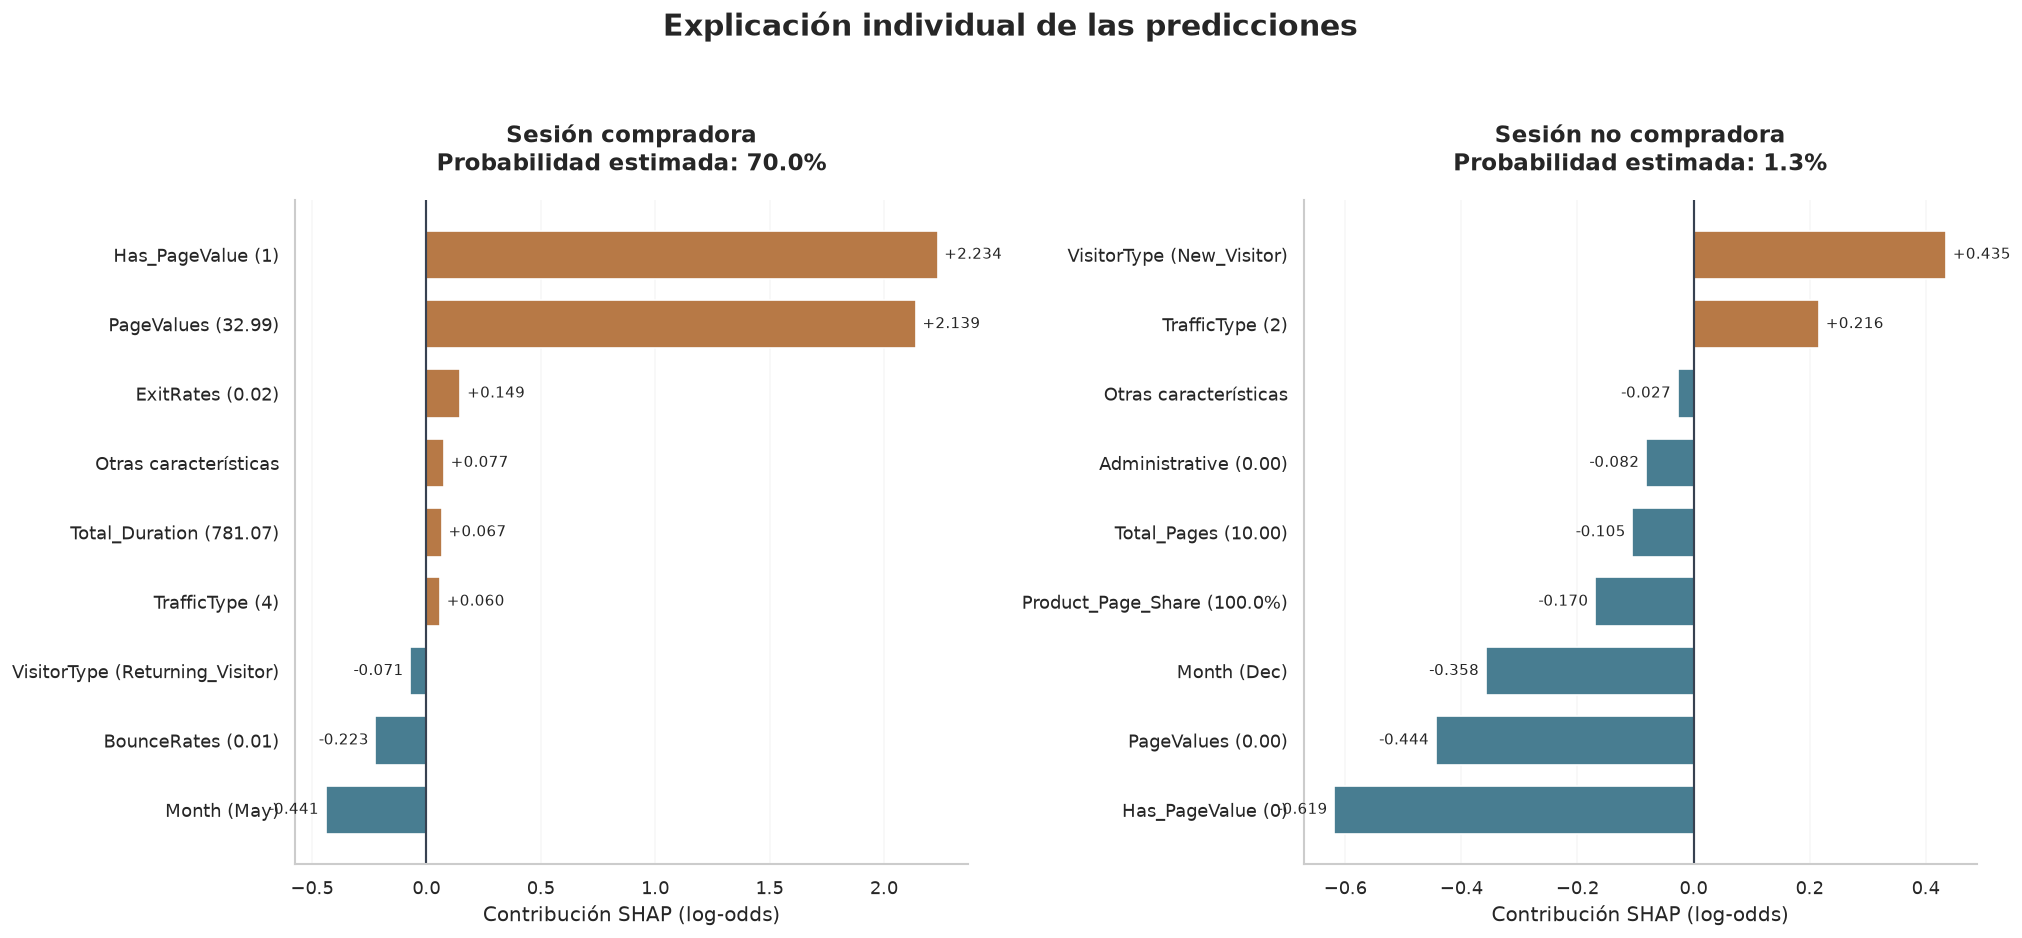

In [39]:
ejemplos = [
    ("Compradora", indices_ejemplo["Compradora"]),
    ("No compradora", indices_ejemplo["No compradora"])
]

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))

for ax, (nombre, indice) in zip(axes, ejemplos):

    shap_sesion = contribuciones.loc[indice]

    # Seleccionar las ocho contribuciones más relevantes
    principales = shap_sesion.abs().nlargest(8).index
    aportaciones = shap_sesion.loc[principales].copy()

    # Agrupar todas las contribuciones restantes
    aportaciones["Otras características"] = (
        shap_sesion.drop(principales).sum()
    )

    aportaciones = aportaciones.sort_values()

    # Etiquetas con el valor observado de cada característica
    etiquetas = []

    for variable in aportaciones.index:

        if variable == "Otras características":
            etiquetas.append(variable)
            continue

        valor = muestra_shap.loc[indice, variable]

        if variable in variables_categoricas:
            valor_texto = str(valor)
        elif variable == "Has_PageValue":
            valor_texto = str(int(valor))
        elif variable == "Product_Page_Share":
            valor_texto = f"{valor:.1%}"
        else:
            valor_texto = f"{valor:.2f}"

        etiquetas.append(f"{variable} ({valor_texto})")

    colores = [
        "#B77946" if valor >= 0 else "#487D91"
        for valor in aportaciones
    ]

    barras = ax.barh(
        etiquetas,
        aportaciones.values,
        color=colores,
        height=0.7
    )

    ax.bar_label(
        barras,
        fmt="%+.3f",
        padding=4,
        fontsize=9
    )

    ax.axvline(
        0,
        color="#374151",
        linewidth=1.3
    )

    probabilidad = probabilidades_muestra.loc[indice]

    ax.set_title(
        f"Sesión {nombre.lower()}\n"
        f"Probabilidad estimada: {probabilidad:.1%}",
        fontsize=14,
        pad=18
    )

    ax.set_xlabel("Contribución SHAP (log-odds)")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.15)
    ax.grid(axis="y", visible=False)

fig.suptitle(
    "Explicación individual de las predicciones",
    fontsize=18,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

**Interpretación**

- **Sesión compradora (70,0 %):** las mayores contribuciones positivas proceden de `Has_PageValue` (+2,234) y `PageValues` (+2,139). Estas compensan las contribuciones negativas de mayo (−0,441) y `BounceRates` (−0,223).


- **Sesión no compradora (1,3 %):** la ausencia de valor de página aporta las principales contribuciones negativas. También destacan diciembre (−0,358) y la navegación exclusivamente por productos (−0,170).


- Aunque la segunda sesión presenta contribuciones positivas de `VisitorType` y `TrafficType`, no son suficientes para compensar las negativas.

**Conclusión:** las explicaciones individuales muestran cómo el modelo combina diferentes señales para estimar la probabilidad de compra. También refuerzan la fuerte dependencia de `PageValues`, aunque sus contribuciones y las de `Has_PageValue` están relacionadas y no constituyen evidencias independientes.

#### 2.9.3. Reconstrucción de las probabilidades

Comprobamos que las contribuciones SHAP reconstruyen las
predicciones de las dos sesiones analizadas.

Sumamos el valor base y las contribuciones de las 22
características en escala log-odds. Después aplicamos
la función logística para obtener la probabilidad de compra.

Esta comprobación verifica la coherencia matemática de las
explicaciones individuales con las predicciones del modelo.

In [40]:
from scipy.special import expit


resultados_locales = []

for nombre, indice in indices_ejemplo.items():

    posicion = muestra_shap.index.get_loc(indice)

    valor_base = valores_base[posicion]
    suma_shap = contribuciones.loc[indice].sum()

    probabilidad_reconstruida = expit(
        valor_base + suma_shap
    )

    probabilidad_modelo = probabilidades_muestra.loc[indice]

    resultados_locales.append({
        "Sesión": nombre,
        "Valor base": valor_base,
        "Suma SHAP": suma_shap,
        "Probabilidad SHAP": probabilidad_reconstruida,
        "Probabilidad CatBoost": probabilidad_modelo,
        "Error absoluto": abs(
            probabilidad_reconstruida - probabilidad_modelo
        )
    })

tabla_locales = pd.DataFrame(resultados_locales)

display(
    tabla_locales.style.format({
        "Valor base": "{:.3f}",
        "Suma SHAP": "{:+.3f}",
        "Probabilidad SHAP": "{:.2%}",
        "Probabilidad CatBoost": "{:.2%}",
        "Error absoluto": "{:.2e}"
    })
)

,Sesión,Valor base,Suma SHAP,Probabilidad SHAP,Probabilidad CatBoost,Error absoluto
0,Compradora,-3.144,+3.992,70.01%,70.01%,5.55e-16
1,No compradora,-3.144,-1.153,1.34%,1.34%,0.00e+00


**Interpretación**

Las probabilidades reconstruidas mediante SHAP coinciden con las predicciones originales de CatBoost:

- **Sesión compradora:** 70,01 % en ambos casos.
- **Sesión no compradora:** 1,34 % en ambos casos.

Los errores absolutos son prácticamente nulos, lo que confirma que las contribuciones SHAP reconstruyen correctamente las predicciones del modelo.

## 3. Interpretabilidad del Random Forest definitivo

Tras la evaluación final del notebook 05, seleccionamos Random Forest por su buen rendimiento y menor complejidad. Por ello, ampliamos el análisis de interpretabilidad para estudiar también el modelo utilizado en NEXUS.

A diferencia de CatBoost, Random Forest utiliza las 17 características originales, sin ingeniería de características adicional.

### 3.1. Carga del modelo y preparación de los datos

Cargamos el pipeline definitivo, que incluye el preprocesamiento y el clasificador entrenado. Utilizaremos las mismas 1.000 sesiones analizadas con CatBoost para facilitar la comparación posterior.

In [41]:
import joblib

# Cargar el Random Forest definitivo
ruta_rf = RAIZ / "models" / "random_forest_final.joblib"

artefacto_rf = joblib.load(ruta_rf)

modelo_rf = artefacto_rf["modelo"]
umbral_rf = float(artefacto_rf["umbral"])

# Recuperar las características originales
columnas_rf = list(modelo_rf.feature_names_in_)

assert columnas_rf == list(X_train.columns)
assert len(columnas_rf) == 17

# Utilizar las mismas sesiones que en CatBoost
muestra_rf = X_train.loc[
    muestra_shap.index, columnas_rf
].copy()

assert muestra_rf.index.equals(muestra_shap.index)

# Comprobar que el modelo predice correctamente
probabilidades_rf = modelo_rf.predict_proba(muestra_rf)[:, 1]

print("Random Forest cargado correctamente.")
print(f"Características: {len(columnas_rf)}")
print(f"Sesiones seleccionadas: {len(muestra_rf):,}")
print(f"Umbral de clasificación: {umbral_rf:.3f}")
print(f"Probabilidad media: {probabilidades_rf.mean():.3f}")

Random Forest cargado correctamente.
Características: 17
Sesiones seleccionadas: 1,000
Umbral de clasificación: 0.365
Probabilidad media: 0.152


### 3.2. Cálculo de las contribuciones SHAP

Calculamos las contribuciones SHAP sobre las mismas 1.000 sesiones utilizadas con CatBoost.

Random Forest aplica One-Hot Encoding a las variables categóricas, por lo que calcularemos SHAP sobre los datos transformados. Después agruparemos las contribuciones para recuperar las 17 características originales.

A diferencia de CatBoost, estas contribuciones se expresan directamente en probabilidad de compra.

In [42]:
import shap

# Separar preprocesamiento y clasificador
preprocesador_rf = modelo_rf[:-1]
bosque_rf = modelo_rf.steps[-1][1]

# Aplicar el preprocesamiento del pipeline
datos_rf_transformados = preprocesador_rf.transform(muestra_rf)

if hasattr(datos_rf_transformados, "toarray"):
    datos_rf_transformados = datos_rf_transformados.toarray()

datos_rf_transformados = np.asarray(
    datos_rf_transformados,
    dtype=np.float64
)

# Calcular SHAP sobre el Random Forest
explicador_rf = shap.TreeExplainer(
    bosque_rf,
    feature_perturbation="tree_path_dependent",
    model_output="raw"
)

valores_shap_rf = explicador_rf.shap_values(
    datos_rf_transformados
)

# Extraer las contribuciones de la clase compradora (Revenue = True)
if isinstance(valores_shap_rf, list):
    contribuciones_rf_codificadas = np.asarray(
        valores_shap_rf[1]
    )
else:
    valores_shap_rf = np.asarray(valores_shap_rf)

    assert valores_shap_rf.ndim == 3
    assert valores_shap_rf.shape[-1] == 2

    contribuciones_rf_codificadas = valores_shap_rf[:, :, 1]

# Valor base para la clase compradora
valor_base_rf = float(
    np.asarray(explicador_rf.expected_value).reshape(-1)[1]
)

# Verificar que SHAP reconstruye las probabilidades originales
probabilidades_reconstruidas_rf = (
    valor_base_rf + contribuciones_rf_codificadas.sum(axis=1)
)

error_rf = np.abs(
    probabilidades_reconstruidas_rf - probabilidades_rf
)

assert np.allclose(
    probabilidades_reconstruidas_rf,
    probabilidades_rf,
    atol=1e-6,
    rtol=0
)

print(f"Sesiones analizadas: {len(muestra_rf):,}")
print(f"Características transformadas: {datos_rf_transformados.shape[1]}")
print(f"Valor base SHAP: {valor_base_rf:.4f}")
print(f"Error máximo de reconstrucción: {error_rf.max():.2e}")
print("Reconstrucción de probabilidades correcta.")

Sesiones analizadas: 1,000
Características transformadas: 74
Valor base SHAP: 0.1564
Error máximo de reconstrucción: 7.88e-15
Reconstrucción de probabilidades correcta.


### 3.3. Agrupación de las características originales

El One-Hot Encoding transforma las variables categóricas en varias columnas. Sumamos sus contribuciones SHAP para recuperar las 17 características originales y facilitar la interpretación.

Comprobamos que esta agrupación conserva las probabilidades predichas.

In [43]:
# Recuperar los nombres de las columnas transformadas
nombres_transformados = [
    nombre.split("__", 1)[-1]
    for nombre in preprocesador_rf.get_feature_names_out()
]

# Agrupar las contribuciones de cada variable original
agrupadas = {}
indices_utilizados = []

for variable in columnas_rf:

    if variable in variables_categoricas:
        indices = [
            i for i, nombre in enumerate(nombres_transformados)
            if nombre.startswith(f"{variable}_")
        ]
    else:
        indices = [
            i for i, nombre in enumerate(nombres_transformados)
            if nombre == variable
        ]

    assert indices, f"No se encontró la variable {variable}"

    indices_utilizados.extend(indices)

    agrupadas[variable] = (
        contribuciones_rf_codificadas[:, indices].sum(axis=1)
    )

# Comprobar que todas las columnas se han utilizado una sola vez
assert sorted(indices_utilizados) == list(
    range(len(nombres_transformados))
)

contribuciones_rf = pd.DataFrame(
    agrupadas,
    index=muestra_rf.index
)

# Verificar nuevamente la reconstrucción
reconstruccion_agrupada = (
    valor_base_rf + contribuciones_rf.sum(axis=1)
)

assert np.allclose(
    reconstruccion_agrupada,
    probabilidades_rf,
    atol=1e-6,
    rtol=0
)

print(f"Características originales: {contribuciones_rf.shape[1]}")
print("Agrupación y reconstrucción correctas.")

Características originales: 17
Agrupación y reconstrucción correctas.


### 3.4. Importancia global de las características

Calculamos la importancia global mediante la media del valor absoluto de las contribuciones SHAP de las 1.000 sesiones.

Representamos las 15 características más influyentes. A diferencia de CatBoost, sus contribuciones están expresadas en unidades de probabilidad.

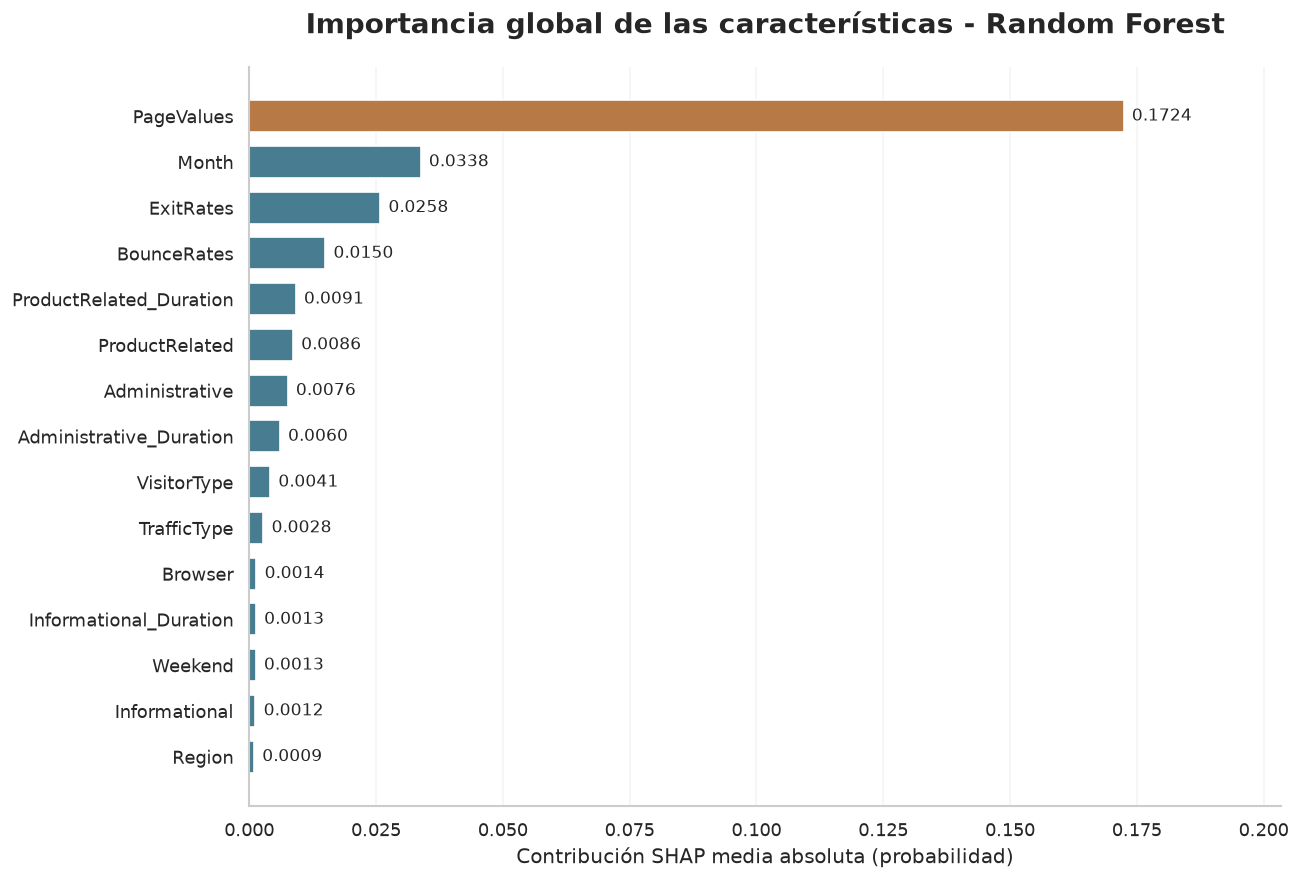

,Importancia SHAP
PageValues,0.172373
Month,0.033769
ExitRates,0.025801
BounceRates,0.014959
ProductRelated_Duration,0.009146
ProductRelated,0.008600
Administrative,0.007556
Administrative_Duration,0.006002
VisitorType,0.004096
TrafficType,0.002763


In [44]:
# Importancia global de las 17 características
importancia_rf = (
    contribuciones_rf.abs()
    .mean()
    .sort_values(ascending=False)
)

top_importancia_rf = importancia_rf.head(15).sort_values()

fig, ax = plt.subplots(figsize=(11, 7.5))

colores = [
    "#B77946" if variable == importancia_rf.index[0]
    else "#487D91"
    for variable in top_importancia_rf.index
]

barras = ax.barh(
    top_importancia_rf.index,
    top_importancia_rf.values,
    color=colores,
    height=0.7
)

ax.bar_label(
    barras,
    fmt="%.4f",
    padding=5,
    fontsize=10
)

ax.set_xlim(0, top_importancia_rf.max() * 1.18)

ax.set_title(
    "Importancia global de las características - Random Forest",
    fontsize=17,
    pad=20
)

ax.set_xlabel(
    "Contribución SHAP media absoluta (probabilidad)"
)
ax.set_ylabel("")

ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

display(importancia_rf.head(10).to_frame("Importancia SHAP"))

**Interpretación**

- **PageValues (0,1724)** domina claramente las predicciones de Random Forest, con una importancia más de cinco veces superior a la de la siguiente característica. Esto confirma su gran relevancia predictiva, observada también en el notebook 03.
- **Month (0,0338)** y **ExitRates (0,0258)** ocupan las siguientes posiciones. También destaca `BounceRates` (0,0150), lo que muestra la importancia de la información temporal y del comportamiento de navegación.
- **ProductRelated_Duration (0,0091)** y **ProductRelated (0,0086)** aportan información adicional, aunque con una influencia bastante menor.

En conjunto, Random Forest depende principalmente de `PageValues`, mientras que el resto de las características tienen contribuciones más moderadas.

### 3.5. Dirección de las contribuciones SHAP

Representamos las contribuciones SHAP de las 13 características más importantes.

Cada punto corresponde a una sesión. Su posición horizontal indica si la característica aumenta o reduce la probabilidad estimada de compra respecto al valor base. El color distingue los valores altos (rojo) y bajos (azul) de las características numéricas; las categóricas aparecen en gris.

Las contribuciones están expresadas en unidades de probabilidad.

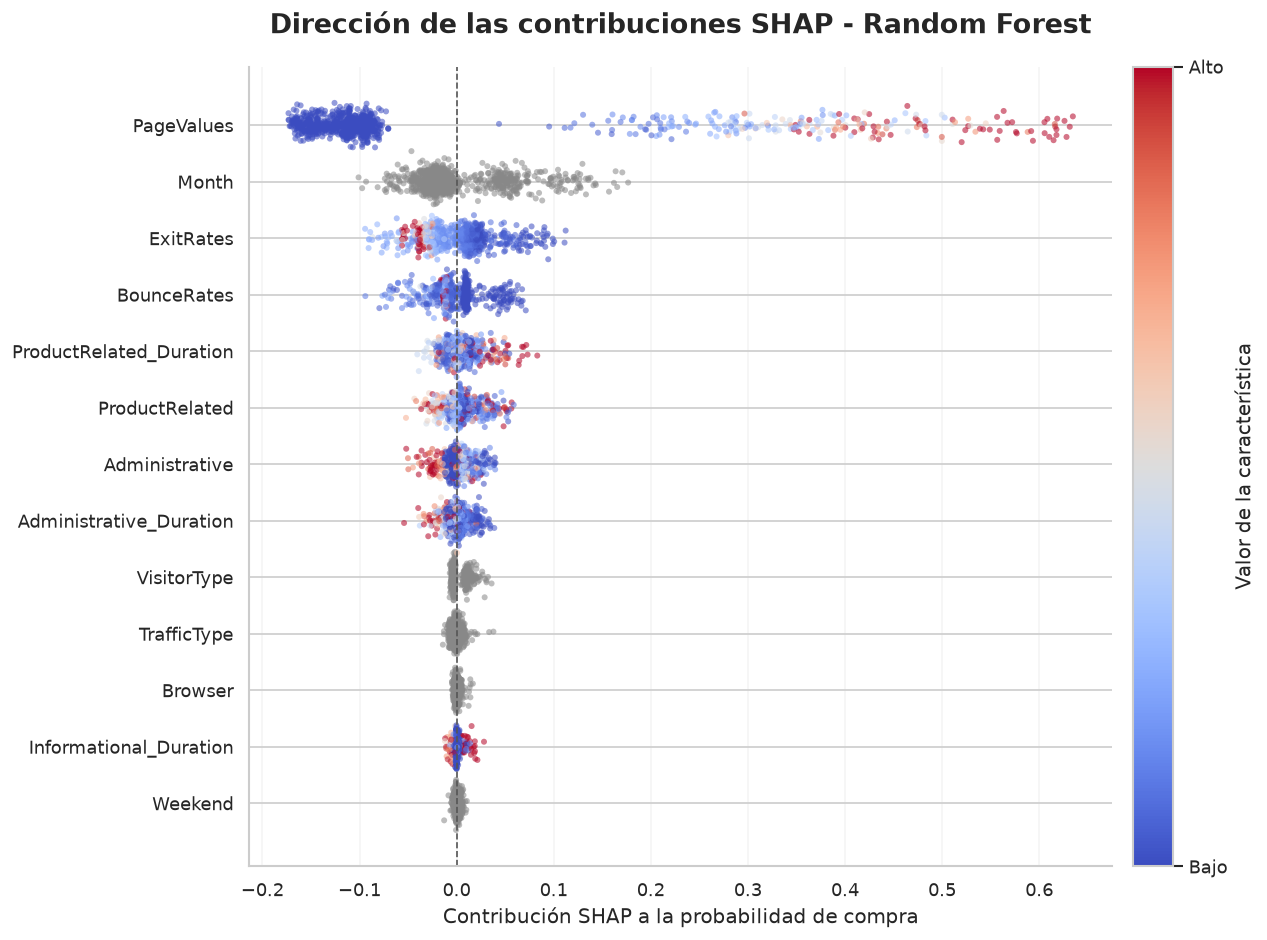

In [45]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

top_variables_rf = importancia_rf.head(13).index[::-1]

fig, ax = plt.subplots(figsize=(11, 8))
rng = np.random.default_rng(42)

for i, variable in enumerate(top_variables_rf):
    valores_shap = contribuciones_rf[variable].to_numpy()
    valores = muestra_rf[variable]

    # Distribución vertical para evitar superposición
    y = i + rng.normal(0, 0.13, len(valores))

    if variable in variables_categoricas:
        colores = "#888888"
    else:
        valores = pd.to_numeric(valores).to_numpy(dtype=float)
        minimo, maximo = np.percentile(valores, [5, 95])

        if maximo > minimo:
            colores = np.clip(
                (valores - minimo) / (maximo - minimo), 0, 1
            )
        else:
            colores = np.full(len(valores), 0.5)

    ax.scatter(
        valores_shap, y,
        c=colores,
        cmap="coolwarm" if variable not in variables_categoricas else None,
        vmin=0 if variable not in variables_categoricas else None,
        vmax=1 if variable not in variables_categoricas else None,
        s=13,
        alpha=0.55,
        edgecolors="none"
    )

ax.axvline(0, color="#555555", linestyle="--", linewidth=1)

ax.set_yticks(range(len(top_variables_rf)))
ax.set_yticklabels(top_variables_rf)

ax.set_xlabel("Contribución SHAP a la probabilidad de compra")
ax.set_title(
    "Dirección de las contribuciones SHAP - Random Forest",
    fontsize=16,
    pad=20
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

# Escala de colores para características numéricas
escala = ScalarMappable(
    norm=Normalize(vmin=0, vmax=1),
    cmap="coolwarm"
)
escala.set_array([])

barra = fig.colorbar(escala, ax=ax, pad=0.02)
barra.set_ticks([0, 1])
barra.set_ticklabels(["Bajo", "Alto"])
barra.set_label("Valor de la característica")

plt.tight_layout()
plt.show()

**Interpretación**

- **PageValues:** es la característica con mayor impacto. Los valores bajos reducen la probabilidad estimada, mientras que los elevados pueden aumentarla considerablemente.
- **Month:** presenta contribuciones positivas y negativas dependiendo del mes, aunque no existe una relación numérica ordenada al tratarse de una variable categórica.
- **ExitRates y BounceRates:** las tasas elevadas tienden a reducir la probabilidad estimada de compra.
- **ProductRelated_Duration:** las duraciones mayores suelen contribuir positivamente, aunque con un efecto mucho menor que `PageValues`.

En conjunto, Random Forest combina el valor de las páginas, la estacionalidad y el comportamiento de navegación, con un claro predominio de `PageValues`.

### 3.6. Relación entre los valores de las características y sus contribuciones

Analizamos cómo varían las contribuciones SHAP según los valores de `PageValues`, `ExitRates` y `ProductRelated_Duration`.

Para facilitar la visualización de las variables con valores muy dispersos, utilizamos una transformación logarítmica en el eje horizontal cuando corresponde.

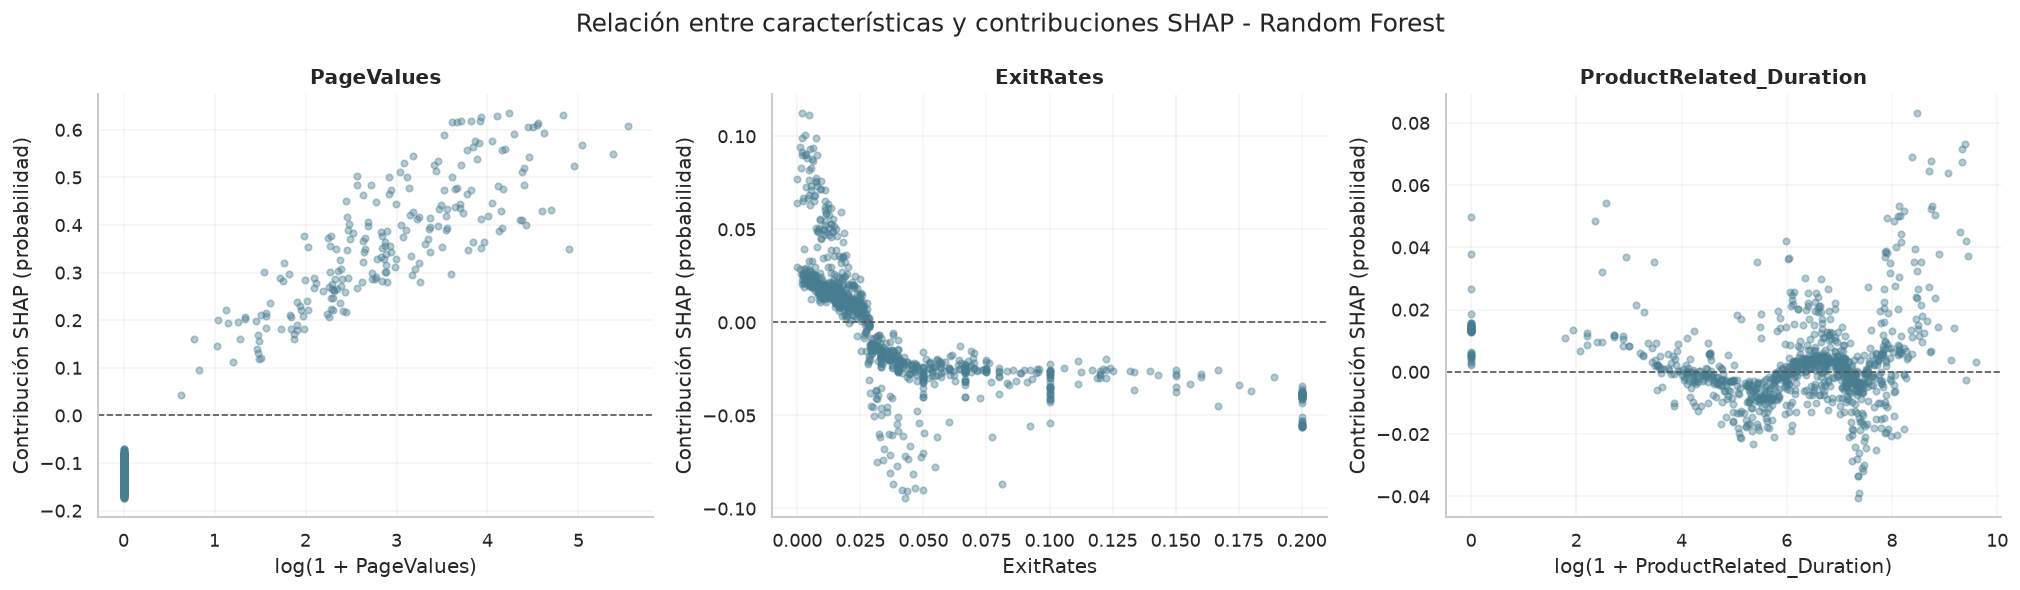

In [46]:
variables_dependencia_rf = [
    "PageValues",
    "ExitRates",
    "ProductRelated_Duration"
]

fig, ejes = plt.subplots(1, 3, figsize=(17, 5))

for ax, variable in zip(ejes, variables_dependencia_rf):
    valores = muestra_rf[variable].to_numpy(dtype=float)
    shap_variable = contribuciones_rf[variable].to_numpy()

    # Transformación únicamente para visualizar
    if variable in ("PageValues", "ProductRelated_Duration"):
        valores = np.log1p(valores)
        etiqueta_x = f"log(1 + {variable})"
    else:
        etiqueta_x = variable

    ax.scatter(
        valores,
        shap_variable,
        s=15,
        alpha=0.4,
        color="#487D91"
    )

    ax.axhline(0, color="#555555", linestyle="--", linewidth=1)
    ax.set_title(variable)
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel("Contribución SHAP (probabilidad)")
    ax.grid(alpha=0.2)

fig.suptitle(
    "Relación entre características y contribuciones SHAP - Random Forest",
    fontsize=15
)

plt.tight_layout()
plt.show()

**Interpretación**

- **PageValues:** los valores nulos contribuyen negativamente, mientras que las contribuciones positivas aumentan claramente conforme crece esta característica.
- **ExitRates:** las tasas más bajas favorecen las predicciones de compra. A medida que aumentan, sus contribuciones pasan a ser predominantemente negativas.
- **ProductRelated_Duration:** presenta contribuciones mucho menores y más dispersas. Las duraciones elevadas pueden favorecer la predicción, pero no existe una relación uniforme. Aun así, podemos distinguir una forma de 'M' en el gráfico, mostrando que si podría haber un patrón o tendencia que siguen.

En conjunto, Random Forest muestra una dependencia muy marcada de `PageValues`, mientras que `ExitRates` y el tiempo de navegación aportan información complementaria.

### 3.7. Explicaciones individuales mediante SHAP

#### 3.7.1. Selección de sesiones

Analizamos las mismas dos sesiones seleccionadas para CatBoost, una compradora y otra no compradora, para facilitar la comparación posterior.

Comenzamos comparando las probabilidades estimadas por ambos modelos.

In [47]:
# Recuperar las mismas sesiones utilizadas con CatBoost
probabilidades_rf_serie = pd.Series(
    probabilidades_rf,
    index=muestra_rf.index
)

tabla_ejemplos_rf = pd.DataFrame({
    "Compra real": [
        y_train.loc[indice]
        for indice in indices_ejemplo.values()
    ],
    "CatBoost": [
        probabilidades_muestra.loc[indice]
        for indice in indices_ejemplo.values()
    ],
    "Random Forest": [
        probabilidades_rf_serie.loc[indice]
        for indice in indices_ejemplo.values()
    ]
}, index=indices_ejemplo.keys())

display(
    tabla_ejemplos_rf.style.format({
        "CatBoost": "{:.1%}",
        "Random Forest": "{:.1%}"
    })
)

,Compra real,CatBoost,Random Forest
Compradora,1,70.0%,64.7%
No compradora,0,1.3%,2.7%


#### 3.7.2. Contribuciones SHAP de las sesiones seleccionadas

Representamos las ocho características con mayores contribuciones absolutas en cada sesión y agrupamos las restantes.

Las contribuciones positivas aumentan la probabilidad estimada respecto al valor base y las negativas la reducen.

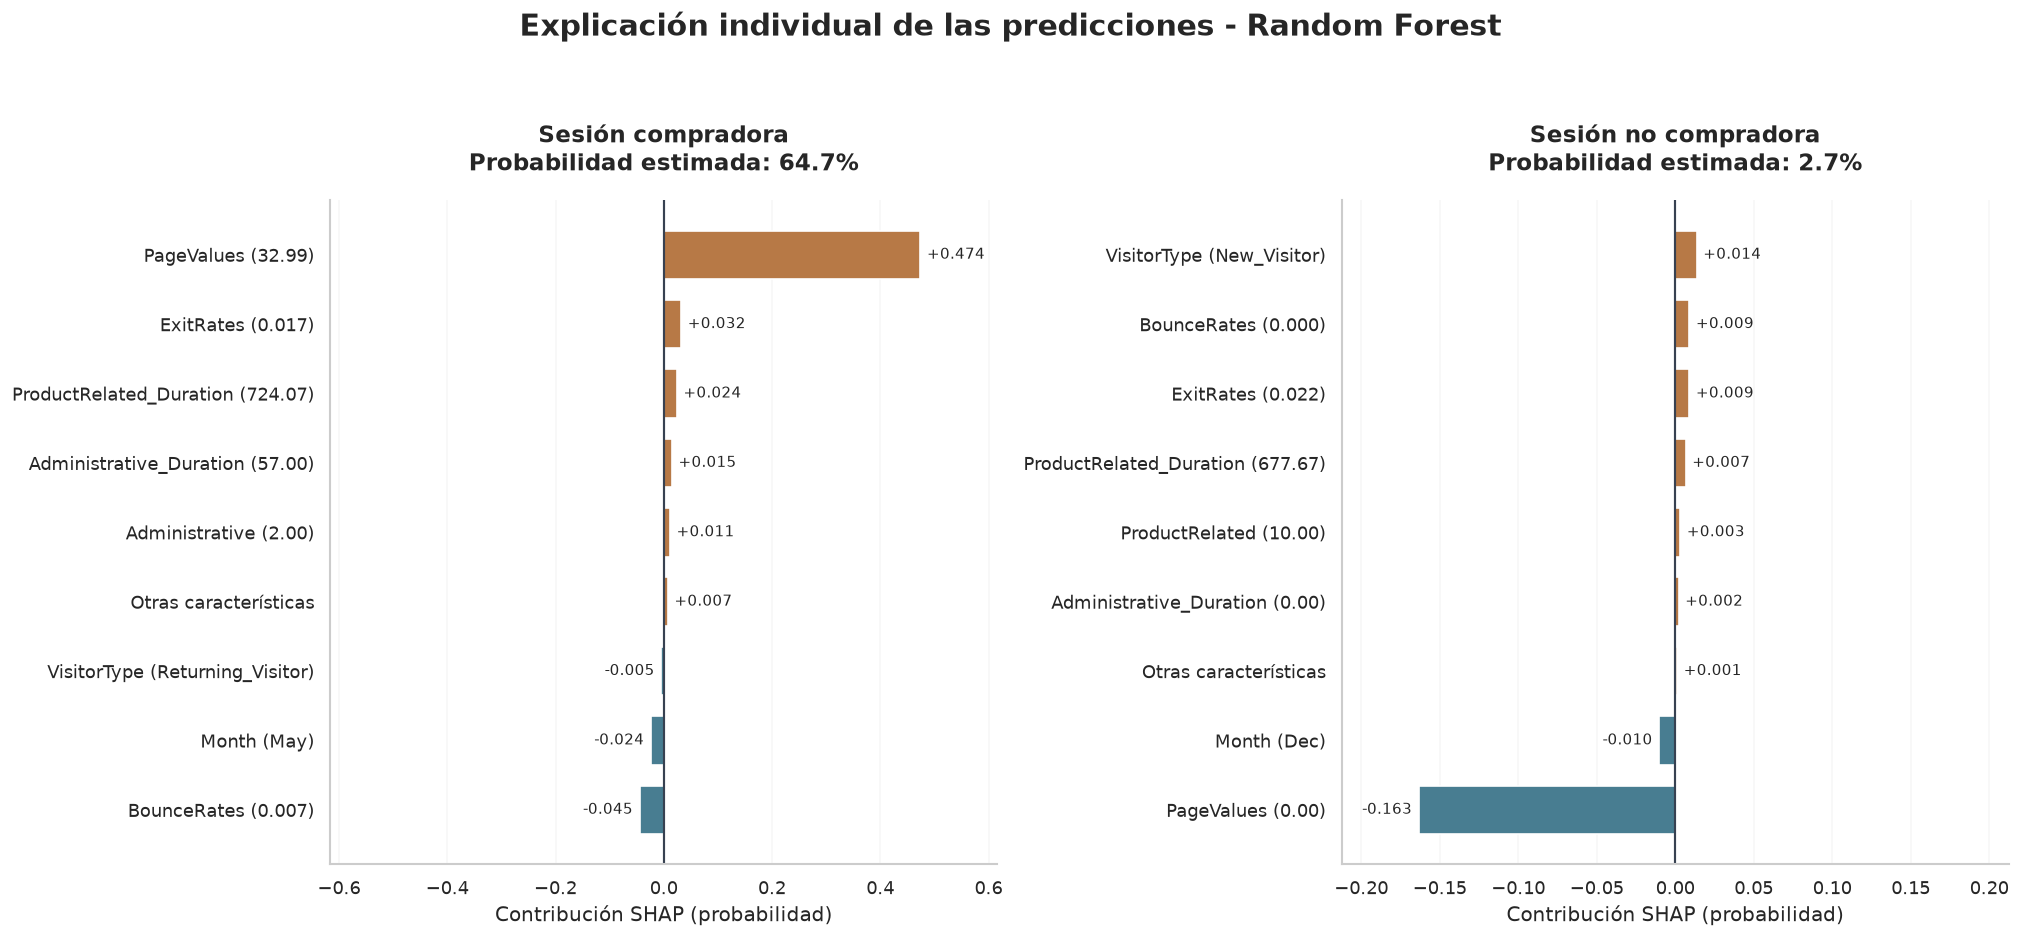

In [48]:
ejemplos_rf = list(indices_ejemplo.items())

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))

for ax, (nombre, indice) in zip(axes, ejemplos_rf):

    shap_sesion = contribuciones_rf.loc[indice]

    # Ocho contribuciones más relevantes
    principales = shap_sesion.abs().nlargest(8).index
    aportaciones = shap_sesion.loc[principales].copy()

    # Agrupar las restantes
    aportaciones["Otras características"] = (
        shap_sesion.drop(principales).sum()
    )

    aportaciones = aportaciones.sort_values()

    # Incluir los valores originales en las etiquetas
    etiquetas = []

    for variable in aportaciones.index:

        if variable == "Otras características":
            etiquetas.append(variable)
            continue

        valor = muestra_rf.loc[indice, variable]

        if variable in variables_categoricas:
            valor_texto = str(valor)
        elif variable in ("ExitRates", "BounceRates"):
            valor_texto = f"{valor:.3f}"
        else:
            valor_texto = f"{valor:.2f}"

        etiquetas.append(f"{variable} ({valor_texto})")

    colores = [
        "#B77946" if valor >= 0 else "#487D91"
        for valor in aportaciones
    ]

    barras = ax.barh(
        etiquetas,
        aportaciones.values,
        color=colores,
        height=0.7
    )

    ax.bar_label(
        barras,
        fmt="%+.3f",
        padding=4,
        fontsize=9
    )

    ax.axvline(0, color="#374151", linewidth=1.3)

    margen = max(aportaciones.abs().max(), 0.02) * 1.3
    ax.set_xlim(-margen, margen)

    probabilidad = probabilidades_rf_serie.loc[indice]

    ax.set_title(
        f"Sesión {nombre.lower()}\n"
        f"Probabilidad estimada: {probabilidad:.1%}",
        fontsize=14,
        pad=18
    )

    ax.set_xlabel("Contribución SHAP (probabilidad)")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.15)
    ax.grid(axis="y", visible=False)

fig.suptitle(
    "Explicación individual de las predicciones - Random Forest",
    fontsize=18,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

**Interpretación**

- **Sesión compradora (64,7 %):** `PageValues` (32,99) es el principal factor positivo, aportando 47,4 puntos porcentuales. `ExitRates` y la duración de navegación también contribuyen positivamente, mientras que `BounceRates` y el mes de mayo reducen ligeramente la predicción.
- **Sesión no compradora (2,7 %):** `PageValues` igual a cero reduce la probabilidad estimada en 16,3 puntos porcentuales. Las demás características tienen contribuciones pequeñas y no compensan esta reducción.

Ambos casos muestran la gran dependencia del modelo respecto a `PageValues`, aunque las contribuciones del resto de características varían según la sesión.

#### 3.7.3. Reconstrucción de las probabilidades

Comprobamos que la suma del valor base y las contribuciones SHAP de cada sesión reproduce exactamente la probabilidad estimada por Random Forest.

In [49]:
resultados_rf_locales = []

for nombre, indice in indices_ejemplo.items():
    contribucion_total = contribuciones_rf.loc[indice].sum()
    probabilidad_reconstruida = valor_base_rf + contribucion_total
    probabilidad_original = probabilidades_rf_serie.loc[indice]

    resultados_rf_locales.append({
        "Sesión": nombre,
        "Valor base": valor_base_rf,
        "Suma SHAP": contribucion_total,
        "Probabilidad reconstruida": probabilidad_reconstruida,
        "Probabilidad original": probabilidad_original,
        "Error absoluto": abs(
            probabilidad_reconstruida - probabilidad_original
        )
    })

tabla_reconstruccion_rf = pd.DataFrame(resultados_rf_locales)

display(
    tabla_reconstruccion_rf.style.format({
        "Valor base": "{:.4f}",
        "Suma SHAP": "{:+.4f}",
        "Probabilidad reconstruida": "{:.4f}",
        "Probabilidad original": "{:.4f}",
        "Error absoluto": "{:.2e}"
    })
)

assert np.allclose(
    tabla_reconstruccion_rf["Probabilidad reconstruida"],
    tabla_reconstruccion_rf["Probabilidad original"],
    atol=1e-6,
    rtol=0
)

,Sesión,Valor base,Suma SHAP,Probabilidad reconstruida,Probabilidad original,Error absoluto
0,Compradora,0.1564,+0.4903,0.6467,0.6467,1.89e-15
1,No compradora,0.1564,-0.1293,0.0271,0.0271,1.11e-15


## 4. Análisis de posibles barreras de conversión

### 4.1. Tasas reales de conversión según la navegación

Las explicaciones SHAP han identificado distintas señales de navegación asociadas con las predicciones de compra.

Para contrastarlas con el comportamiento observado, analizaremos la **tasa real de conversión** según los valores de tres indicadores: ExitRates, ProductRelated_Duration y Product_Page_Share.

Dividiremos las dos primeras variables en cuartiles. Para Product_Page_Share utilizaremos intervalos específicos que permitan distinguir las sesiones dedicadas exclusivamente a páginas de productos.

Este análisis ayudará a identificar patrones que podrían revelar puntos de fricción comercial.

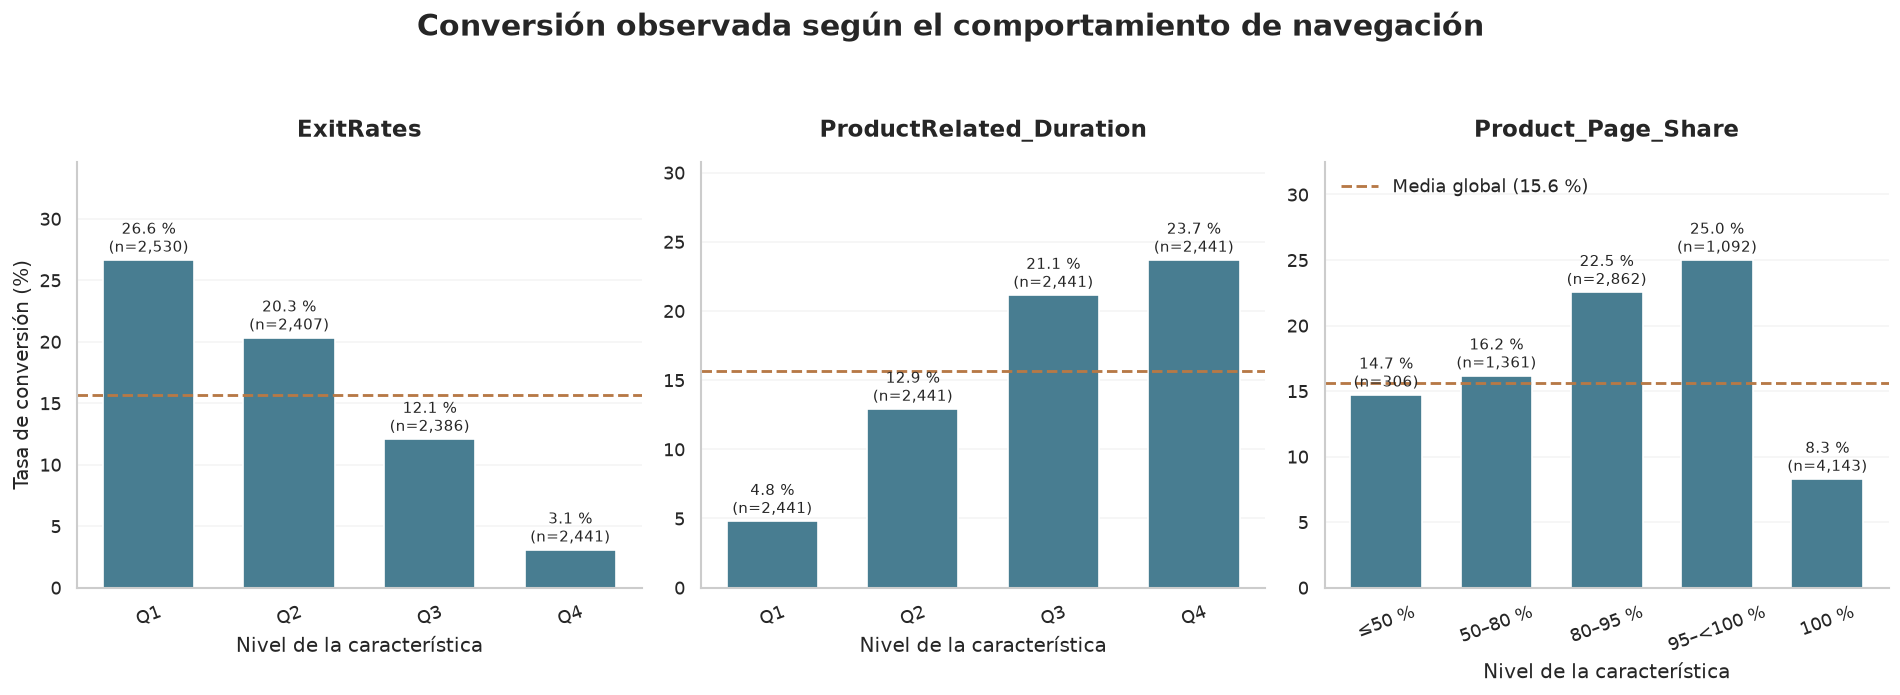

,Variable,Grupo,Intervalo,Sesiones,Conversión (%)
0,ExitRates,Q1,"(-0.001, 0.0143]","2,530",26.6
1,ExitRates,Q2,"(0.0143, 0.025]","2,407",20.3
2,ExitRates,Q3,"(0.025, 0.0492]","2,386",12.1
3,ExitRates,Q4,"(0.0492, 0.2]","2,441",3.1
4,ProductRelated_Duration,Q1,"(-0.001, 193.467]","2,441",4.8
5,ProductRelated_Duration,Q2,"(193.467, 617.0]","2,441",12.9
6,ProductRelated_Duration,Q3,"(617.0, 1483.65]","2,441",21.1
7,ProductRelated_Duration,Q4,"(1483.65, 63973.522]","2,441",23.7
8,Product_Page_Share,≤50 %,≤50 %,306,14.7
9,Product_Page_Share,50–80 %,50–80 %,"1,361",16.2


In [50]:
grupos_analisis = {
    "ExitRates": pd.qcut(
        X_train_cb["ExitRates"], q=4, duplicates="drop"
    ),
    "ProductRelated_Duration": pd.qcut(
        X_train_cb["ProductRelated_Duration"],
        q=4,
        duplicates="drop"
    ),
    "Product_Page_Share": pd.cut(
        X_train_cb["Product_Page_Share"],
        bins=[-0.001, 0.50, 0.80, 0.95, 0.999999, 1.0],
        labels=["≤50 %", "50–80 %", "80–95 %", "95–<100 %", "100 %"]
    )
}

conversion_global = y_train.mean() * 100
resultados_conversion = []

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))

for ax, (variable, grupos) in zip(
    axes, grupos_analisis.items()
):

    temporal = pd.DataFrame({
        "Grupo": grupos,
        "Revenue": y_train
    })

    resumen = (
        temporal.groupby("Grupo", observed=True)["Revenue"]
        .agg(["mean", "size"])
        .reset_index()
    )

    resumen["Conversión (%)"] = resumen["mean"] * 100

    etiquetas = (
        resumen["Grupo"].astype(str).tolist()
        if variable == "Product_Page_Share"
        else [f"Q{i+1}" for i in range(len(resumen))]
    )

    barras = ax.bar(
        etiquetas,
        resumen["Conversión (%)"],
        color="#487D91",
        width=0.65
    )

    ax.axhline(
        conversion_global,
        color="#B77946",
        linestyle="--",
        linewidth=1.7,
        label=f"Media global ({conversion_global:.1f} %)"
    )

    for barra, tasa, n in zip(
        barras, resumen["Conversión (%)"], resumen["size"]
    ):
        ax.annotate(
            f"{tasa:.1f} %\n(n={n:,})",
            (
                barra.get_x() + barra.get_width() / 2,
                barra.get_height()
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    for etiqueta, (_, fila) in zip(
        etiquetas, resumen.iterrows()
    ):
        resultados_conversion.append({
            "Variable": variable,
            "Grupo": etiqueta,
            "Intervalo": str(fila["Grupo"]),
            "Sesiones": fila["size"],
            "Conversión (%)": fila["Conversión (%)"]
        })

    ax.set_title(variable, fontsize=14, pad=15)
    ax.set_xlabel("Nivel de la característica")
    ax.set_ylim(
        0,
        max(resumen["Conversión (%)"].max(), conversion_global) * 1.3
    )
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.2)
    ax.grid(axis="x", visible=False)

axes[0].set_ylabel("Tasa de conversión (%)")
axes[2].legend(frameon=False, loc="upper left")

fig.suptitle(
    "Conversión observada según el comportamiento de navegación",
    fontsize=18,
    fontweight="bold",
    y=1.05
)

plt.tight_layout()
plt.show()

tabla_conversion = pd.DataFrame(resultados_conversion)

display(
    tabla_conversion.style.format({
        "Sesiones": "{:,.0f}",
        "Conversión (%)": "{:.1f}"
    })
)

**Interpretación**

- **ExitRates:** la conversión disminuye progresivamente del **26,6 % al 3,1 %** entre el primer y el último cuartil. Es la señal más clara de abandono entre las analizadas.


- **ProductRelated_Duration:** las sesiones con mayor tiempo de navegación por productos presentan tasas de compra superiores, desde el **4,8 % hasta el 23,7 %**.


- **Product_Page_Share:** la conversión aumenta hasta el **25,0 %** cuando los productos representan entre el 95 % y el 100 % de las páginas visitadas, pero cae al **8,3 %** cuando representan exactamente el 100 %.

**Hallazgo principal:** las sesiones dedicadas exclusivamente a páginas de productos convierten mucho menos que aquellas que también incluyen otros tipos de páginas. Esta diferencia la investigaremos antes de interpretarla como una posible barrera de compra.

### 4.2. Navegación exclusivamente por productos
La tasa de conversión cae notablemente cuando todas las páginas visitadas corresponden a productos.

Sin embargo, esta diferencia podría estar relacionada con la duración o profundidad de la sesión, y no necesariamente con el tipo de páginas visitadas.

Para investigarlo, comparamos las tasas de conversión de las sesiones con una proporción de páginas de productos entre el 80 % y menos del 100 %, frente a las que alcanzan exactamente el 100 %, distinguiendo tres niveles de actividad según el número de páginas visitadas.

In [51]:
datos_share = X_train_cb.loc[
    X_train_cb["Product_Page_Share"] >= 0.80,
    ["Product_Page_Share", "Total_Pages"]
].copy()

datos_share["Revenue"] = y_train.loc[datos_share.index]

datos_share["Tipo de navegación"] = np.where(
    datos_share["Product_Page_Share"] == 1,
    "100 % productos",
    "80–<100 % productos"
)

datos_share["Actividad"] = pd.cut(
    datos_share["Total_Pages"],
    bins=[0, 5, 20, np.inf],
    labels=["1–5 páginas", "6–20 páginas", ">20 páginas"],
    include_lowest=True
)

resumen_share = (
    datos_share
    .groupby(
        ["Actividad", "Tipo de navegación"],
        observed=True
    )["Revenue"]
    .agg(Sesiones="size", Conversion="mean")
    .reset_index()
)

resumen_share["Conversión (%)"] = (
    resumen_share["Conversion"] * 100
)

display(
    resumen_share[
        ["Actividad", "Tipo de navegación",
         "Sesiones", "Conversión (%)"]
    ].style.format({
        "Sesiones": "{:,.0f}",
        "Conversión (%)": "{:.1f}"
    })
)

,Actividad,Tipo de navegación,Sesiones,Conversión (%)
0,1–5 páginas,100 % productos,"1,367",1.8
1,1–5 páginas,80–<100 % productos,20,10.0
2,6–20 páginas,100 % productos,"1,739",9.8
3,6–20 páginas,80–<100 % productos,793,18.0
4,>20 páginas,100 % productos,"1,037",14.2
5,>20 páginas,80–<100 % productos,"3,241",24.6


**Interpretación**

- La conversión aumenta con el número de páginas visitadas, tanto en sesiones exclusivas de productos como en sesiones mixtas.


- Sin embargo, la diferencia persiste al comparar niveles de actividad similares: **9,8 % frente a 18,0 %** entre 6–20 páginas, y **14,2 % frente a 24,6 %** cuando se superan las 20 páginas.


- La comparación de sesiones de 1–5 páginas es menos fiable por el reducido tamaño del grupo de navegación mixta (20 sesiones).

**Hallazgo:** el menor rendimiento de las sesiones dedicadas exclusivamente a productos no parece explicarse únicamente por una navegación más corta.

Este patrón sugiere investigar qué otras acciones realizan los usuarios que consultan diferentes tipos de páginas. No obstante, los datos agregados no permiten identificar las etapas exactas de abandono ni establecer relaciones causales.

**Posible explicación**

Una hipótesis es que las sesiones dedicadas exclusivamente a productos correspondan con mayor frecuencia a usuarios que exploran o comparan artículos sin intención inmediata de compra. En cambio, visitar también páginas administrativas o informativas podría reflejar una fase más avanzada del proceso de compra.

No obstante, desconocemos las páginas concretas y el orden de navegación. Por tanto, esta interpretación es una hipótesis que requeriría datos de navegación más detallados para contrastarse.

## 5. Comparación y conclusiones

### 5.1. Comparación de la interpretabilidad

Los dos modelos identifican patrones similares, aunque conceden distinta importancia a las características:

- **CatBoost:** destacan `Month`, `Has_PageValue` y `PageValues`. La información temporal tiene una influencia especialmente elevada.
- **Random Forest:** `PageValues` domina claramente, seguida de `Month`, `ExitRates` y `BounceRates`.
- **Navegación:** ambos modelos utilizan las tasas de salida y rebote, así como la actividad del usuario, para diferenciar las sesiones.

La comparación debe interpretarse con cautela: CatBoost utiliza 22 características y contribuciones en *log-odds*, mientras que Random Forest emplea 17 características y contribuciones en probabilidad. Por ello, sus importancias SHAP no son directamente comparables en magnitud.

### 5.2. Comparación de las explicaciones individuales

Al analizar las mismas dos sesiones, ambos modelos ofrecen predicciones similares:

| Sesión | CatBoost | Random Forest |
|---|---:|---:|
| Compradora | 70,01 % | 64,7 % |
| No compradora | 1,34 % | 2,7 % |

En ambos casos, las características relacionadas con `PageValues` son determinantes. Los dos modelos identifican correctamente estos ejemplos, aunque distribuyen las contribuciones entre las variables de forma diferente.

### 5.3. Conclusiones

El análisis SHAP muestra que ambos modelos utilizan principalmente indicadores del valor de las páginas, información temporal y características de navegación.

Random Forest presenta una dependencia especialmente marcada de `PageValues`, mientras que CatBoost reparte más importancia entre distintas características, incluidas algunas derivadas.

El análisis de las tasas reales de conversión permite contrastar parte de estos patrones y plantear posibles barreras de compra. Sin embargo, las contribuciones SHAP describen asociaciones aprendidas por los modelos, no relaciones causales.

Finalmente, aunque Random Forest fue seleccionado como modelo definitivo y se utiliza en NEXUS, su dependencia de `PageValues` sigue siendo una limitación importante para una aplicación real, debido a las dudas sobre la disponibilidad de esta información en el momento de realizar la predicción.